# Clasificación de asteroides potencialmente peligrosos

**Introducción a la Inteligencia Artificial** · 6.º semestre

**Integrantes:** Dylan Alexander Mejia Ceballos · Luis Miguel Brito Rincon · Gabriel Alejandro Giraldo Ayerbe · Juan Pablo Muñoz Corchos · Juan Pablo Agudelo · Evelyn Gómez Aristizabal

La NASA marca un asteroide como *potencialmente peligroso* (PHA) cuando su órbita pasa cerca de la de la Tierra y además es grande. En este notebook probamos si un modelo de machine learning puede reconocerlos a partir de sus datos físicos y orbitales.

- **Datos:** `nasa.csv`, 4,687 acercamientos de 3,692 asteroides distintos, 40 columnas.
- **Variable objetivo:** `Hazardous` (1 = peligroso, 0 = no peligroso).
- **Metodología:** ASUM-DM (IBM). Cada fase de la metodología es una sección del notebook.
- **Complemento:** en `catalogo_jpl_asteroides.ipynb` repetimos la prueba con el catálogo completo del JPL y con asteroides descubiertos entre 2024 y 2026.

## Contenido

0. [Configuración del entorno](#s0)
1. [El problema](#s1) · *Analyze*
   - [1.1 Qué hace peligroso a un asteroide](#s1-1)
   - [1.2 Tres escenarios: con y sin la regla](#s1-2)
   - [1.3 Cómo medimos el éxito](#s1-3)
   - [1.4 Carga de datos y verificación de la regla](#s1-4)
   - [1.5 Desbalance de clases](#s1-5)
2. [Diseño del experimento](#s2) · *Design*
   - [2.1 Limpieza de columnas y escenarios](#s2-1)
   - [2.2 Partición agrupada por asteroide](#s2-2)
   - [2.3 Medición de la fuga](#s2-3)
3. [Preparación y análisis de los datos](#s3) · *Configure & Build*
   - [3.1 Análisis exploratorio](#s3-1)
   - [3.2 Escalado y normalización](#s3-2)
   - [3.3 Reducción de dimensionalidad con PCA](#s3-3)
   - [3.4 Selección de variables](#s3-4)
   - [3.5 SHAP: qué variables pesan más](#s3-5)
   - [3.6 Comparación de los métodos de selección](#s3-6)
   - [3.7 ¿Se puede calcular el MOID desde la órbita?](#s3-7)
4. [Modelado](#s4) · *Configure & Build*
   - [4.1 Sesgo y varianza con k-NN](#s4-1)
   - [4.2 Ajuste de hiperparámetros con RandomizedSearchCV](#s4-2)
   - [4.3 Comparación de 13 clasificadores con validación cruzada repetida](#s4-3)
   - [4.4 Qué modelos aguantan sin el MOID](#s4-4)
5. [Evaluación](#s5) · *Configure & Build*
   - [5.1 Umbral F2 en Validación y tasa de alertas](#s5-1)
   - [5.2 Pruebas de sobreajuste](#s5-2)
   - [5.3 Evaluación en Test](#s5-3)
   - [5.4 Modelo final: reportes y matrices de confusión](#s5-4)
   - [5.5 Curvas ROC y Precision-Recall](#s5-5)
   - [5.6 Intervalos de confianza en Test](#s5-6)
6. [Despliegue](#s6) · *Deploy*
   - [6.1 Guardar el modelo y las métricas](#s6-1)
   - [6.2 Función de predicción](#s6-2)
7. [Monitoreo](#s7) · *Operate & Optimize*
   - [7.1 Drift de datos con PSI](#s7-1)
   - [7.2 Plan de monitoreo](#s7-2)
8. [Resultados y conclusiones](#s8)
   - [8.1 Cifras clave](#s8-1)
   - [8.2 Datos para la presentación](#s8-2)
   - [8.3 Conclusiones](#s8-3)

### Dónde está cada tema

| Tema | Sección |
| :--- | :--- |
| Validación cruzada agrupada (`StratifiedGroupKFold`) | [2.2](#s2-2), [2.3](#s2-3) |
| Análisis exploratorio (pairplot, correlación $\phi_K$) | [3.1](#s3-1) |
| Escalado (`StandardScaler`, `MinMaxScaler`, `RobustScaler`) | [3.2](#s3-2) |
| PCA (varianza explicada, proyección 2D) | [3.3](#s3-3) |
| Selección de variables: filtro, wrapper (`RFECV`) y embedded ($L_1$, árboles) | [3.4](#s3-4), [3.6](#s3-6) |
| SHAP | [3.5](#s3-5) |
| Cálculo del MOID desde la órbita y variables de geometría orbital | [3.7](#s3-7) |
| Sesgo y varianza | [4.1](#s4-1), [5.2](#s5-2) |
| Ajuste de hiperparámetros (`RandomizedSearchCV`) | [4.2](#s4-2) |
| Validación cruzada repetida con varias semillas | [4.3](#s4-3) |
| Clasificadores y ensambles (Bagging, AdaBoost, Random Forest, HistGradientBoosting, Stacking…) | [4.3](#s4-3) |
| Umbral de decisión con $F_2$ y tasa de alertas | [5.1](#s5-1), [5.3](#s5-3) |
| Sobreajuste: curva de aprendizaje e importancia por permutación | [5.2](#s5-2) |
| Matriz de confusión y reporte de clasificación | [5.4](#s5-4) |
| Curvas ROC y Precision-Recall | [5.5](#s5-5) |
| Intervalos de confianza (bootstrap) | [5.6](#s5-6) |
| Modelo guardado y función de predicción | [6.1](#s6-1), [6.2](#s6-2) |
| Monitoreo (PSI) | [7.1](#s7-1) |
| Conclusiones | [8.3](#s8-3) |

<a id="s0"></a>
## 0. Configuración del entorno

Librerías, semilla (`SEED = 42`), métricas y dos funciones que usamos en todo el notebook: `hacer_pipeline` (imputación, escalado opcional y clasificador dentro de un `Pipeline`) y `resumir_cv` (media y desviación estándar de cada métrica en la validación cruzada). Cada proceso de entrenamiento en paralelo usa 2 hilos (`OMP_NUM_THREADS`) para que los modelos no compitan por los núcleos.

In [1]:
# 0. Configuración del entorno, librerías y funciones auxiliares
import os

# En Windows 11 joblib/loky intenta usar `wmic` (ya no existe) y muestra un error; fijar el número de núcleos lo evita.
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(max(1, (os.cpu_count() or 2) // 2)))
# Muchos modelos se entrenan en paralelo; con 2 hilos de OpenMP por proceso no se pisan entre ellos
os.environ.setdefault('OMP_NUM_THREADS', '2')

import warnings
import json
from datetime import datetime
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint, uniform

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_validate,
    RandomizedSearchCV,
    learning_curve
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import (
    mutual_info_classif,
    SelectKBest,
    RFE,
    RFECV,
    SelectFromModel
)
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve,
    make_scorer
)

# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
    BaggingClassifier,
    StackingClassifier
)
from sklearn.neural_network import MLPClassifier

# Correlación no lineal y SHAP
import phik
from phik.report import plot_correlation_matrix
import shap

# Configuración visual
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.max_colwidth', None)
COLORES_CLASE = {0: '#4C72B0', 1: '#D1495B'}

SEED = 42
np.random.seed(SEED)

# Carpeta donde se guardan las métricas (JSON/CSV)
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)

# Métricas de todas las validaciones cruzadas ('pr_auc' es 'average_precision' en scikit-learn)
SCORING: dict[str, Any] = {
    'f1': 'f1',
    'f2': make_scorer(fbeta_score, beta=2),
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
    'accuracy': 'accuracy'
}


def hacer_pipeline(clf: BaseEstimator, escalador: Any = None) -> Pipeline:
    """Pipeline con imputación por mediana, escalado opcional y clasificador.

    Todos los pasos se ajustan solo con los datos de entrenamiento de cada fold.
    """
    pasos: list[tuple[str, Any]] = [('imputer', SimpleImputer(strategy='median'))]
    if escalador is not None:
        pasos.append(('scaler', clone(escalador) if not isinstance(escalador, str) else escalador))
    pasos.append(('clf', clf))
    return Pipeline(pasos)


def resumir_cv(res: dict[str, np.ndarray], metricas: list[str]) -> dict[str, float]:
    """Convierte la salida de cross_validate en medias y desviaciones estándar por métrica."""
    out: dict[str, float] = {}
    for m in metricas:
        out[m] = float(np.mean(res[f'test_{m}']))
        out[f'{m}_std'] = float(np.std(res[f'test_{m}']))
    return out


print('Versiones:')
print(f'  · scikit-learn : {sklearn.__version__}')
print(f'  · shap         : {shap.__version__}')
print(f'  · phik         : {phik.__version__}')

Versiones:
  · scikit-learn : 1.6.1
  · shap         : 0.53.0
  · phik         : 0.12.5


<a id="s1"></a>
## 1. El problema (Analyze)

<a id="s1-1"></a>
### 1.1 Qué hace peligroso a un asteroide

El JPL/CNEOS de la NASA clasifica un asteroide cercano a la Tierra (NEO) como potencialmente peligroso (PHA) si cumple dos condiciones a la vez:

$$\text{PHA} \iff \text{MOID} \le 0.05\text{ UA} \quad \land \quad H \le 22.0$$

- **MOID** (*Minimum Orbit Intersection Distance*): la distancia mínima entre la órbita del asteroide y la de la Tierra. 0.05 UA son unos 7.48 millones de km, cerca de 19.5 veces la distancia a la Luna.
- **H** (magnitud absoluta): mide el brillo del asteroide; entre más pequeño el número, más grande el objeto. $H \le 22.0$ equivale más o menos a 140 m de diámetro o más.

<a id="s1-2"></a>
### 1.2 Tres escenarios: con y sin la regla

Si le damos al modelo `Minimum Orbit Intersection` y `Absolute Magnitude`, un árbol de decisión encuentra la regla de arriba casi sin esfuerzo (F1 > 98%), y eso no demuestra que aprenda algo. Por eso armamos tres escenarios, quitando cada vez más información:

| Escenario | Qué se quita | Para qué |
| :--- | :--- | :--- |
| A. Completo | Nada | Referencia: el modelo puede copiar la regla |
| B. Sin MOID | `Minimum Orbit Intersection` | El caso realista: el modelo tiene que deducir la cercanía a partir de la órbita (excentricidad, semieje mayor, inclinación, perihelio…) |
| C. Sin definición | MOID, magnitud absoluta y diámetro | El caso difícil: sin ninguna de las dos condiciones |

El modelo que guardamos al final es el del escenario B.

<a id="s1-3"></a>
### 1.3 Cómo medimos el éxito

Solo el 16.1% de los acercamientos son peligrosos. Un modelo que diga siempre "no peligroso" ya tendría 84% de accuracy, así que el accuracy no sirve para comparar. Además, el error más grave es el falso negativo: no avisar de un asteroide que sí es peligroso. Por eso usamos:

- **Recall:** de los peligrosos, cuántos detecta.
- **PR-AUC** (*average precision*): resume la curva precisión-recall. Es la métrica principal para comparar modelos.
- **F2:** combina precisión y recall, pero el recall pesa el doble.

<a id="s1-4"></a>
### 1.4 Carga de datos y verificación de la regla

Cargamos `nasa.csv`, revisamos nulos, duplicados y asteroides repetidos, y comprobamos qué tanto coincide la regla de la NASA con la etiqueta `Hazardous`.

In [2]:
# 1.4 Carga de datos, revisión y verificación de la regla de CNEOS
data = pd.read_csv('nasa.csv')
TARGET = 'Hazardous'
assert data.shape == (4687, 40), f'Dimensión inesperada del dataset: {data.shape}'
data[TARGET] = data[TARGET].astype(int)  # {False: 0, True: 1}

print(f'Tamaño del dataset: {data.shape[0]} filas x {data.shape[1]} columnas')
print(f'Valores nulos: {data.isnull().sum().sum()} | Duplicados exactos: {data.duplicated().sum()}')
print(f"Asteroides únicos: {data['Neo Reference ID'].nunique()} | "
      f"Asteroides con más de un acercamiento: {(data['Neo Reference ID'].value_counts() > 1).sum()}")

# ¿Qué tanto coincide la regla de la NASA con la etiqueta?
rule_mask = ((data['Minimum Orbit Intersection'] <= 0.05) & (data['Absolute Magnitude'] <= 22.0)).astype(int)
ACUERDO_REGLA = float((rule_mask == data[TARGET]).mean())
print(f'La regla de la NASA coincide con la etiqueta en el {ACUERDO_REGLA:.2%} de las filas')
crosstab_rule = pd.crosstab(rule_mask.rename('Regla NASA'), data[TARGET].rename('Etiqueta Real'))
display(crosstab_rule)

Tamaño del dataset: 4687 filas x 40 columnas
Valores nulos: 0 | Duplicados exactos: 0
Asteroides únicos: 3692 | Asteroides con más de un acercamiento: 751
La regla de la NASA coincide con la etiqueta en el 99.55% de las filas


Etiqueta Real,0,1
Regla NASA,,
0,3923,12
1,9,743


<a id="s1-5"></a>
### 1.5 Desbalance de clases

Cuántos acercamientos hay de cada clase, cómo se reparte H en cada una y las medianas de las variables físicas.

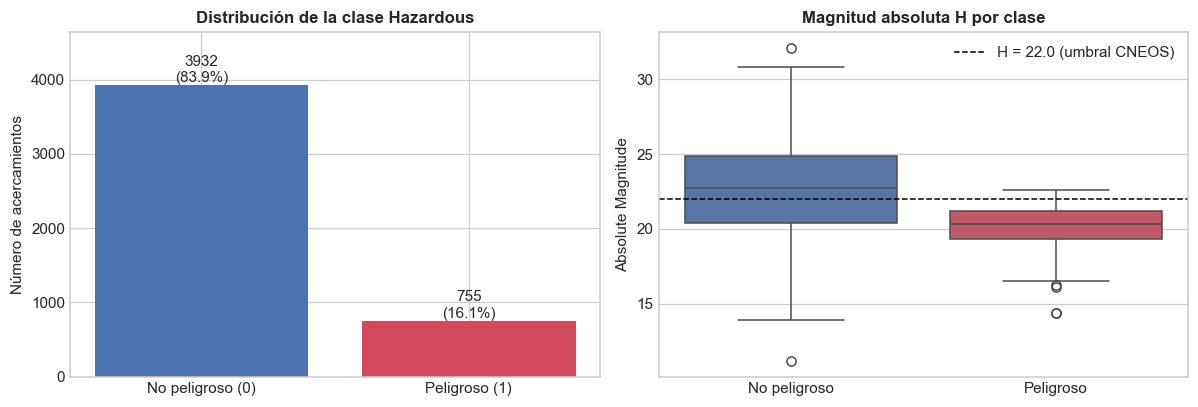

Desbalance: 83.9% no peligrosos vs 16.1% peligrosos -> un clasificador que siempre diga "no peligroso" tendría accuracy = 83.9%.


,Mediana No peligroso,Mediana Peligroso,mean,std,min,max
Absolute Magnitude,22.700,20.300,22.268,2.891,11.160,32.100
Est Dia in KM(min),0.077,0.232,0.205,0.370,0.001,15.580
Relative Velocity km per sec,12.298,15.608,13.971,7.293,0.336,44.634
Miss Dist.(Astronomical),0.263,0.281,0.257,0.146,0.000,0.500
Minimum Orbit Intersection,0.064,0.023,0.082,0.090,0.000,0.478
Orbit Uncertainity,5.000,0.000,3.517,3.078,0.000,9.000
Jupiter Tisserand Invariant,5.062,5.094,5.056,1.238,2.196,9.025
Eccentricity,0.357,0.452,0.383,0.180,0.008,0.960
Semi Major Axis,1.246,1.226,1.400,0.524,0.616,5.072
Inclination,10.426,9.787,13.374,10.936,0.015,75.407


In [3]:
# 1.5 Distribución de la clase y estadística descriptiva
ETIQUETAS_CLASE = {0: 'No peligroso', 1: 'Peligroso'}
PALETA_ETIQUETAS = {ETIQUETAS_CLASE[k]: v for k, v in COLORES_CLASE.items()}
conteo = data[TARGET].value_counts().sort_index()
pct = data[TARGET].value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar([f'{ETIQUETAS_CLASE[k]} ({k})' for k in conteo.index], conteo.values, color=[COLORES_CLASE[k] for k in conteo.index])
for i, (n, p) in enumerate(zip(conteo.values, pct.values)):
    axes[0].text(i, n, f'{n}\n({p:.1%})', ha='center', va='bottom')
axes[0].set_title('Distribución de la clase Hazardous')
axes[0].set_ylabel('Número de acercamientos')
axes[0].set_ylim(0, conteo.max() * 1.18)

datos_box = data.assign(Clase=data[TARGET].map(ETIQUETAS_CLASE))
sns.boxplot(data=datos_box, x='Clase', y='Absolute Magnitude', hue='Clase', palette=PALETA_ETIQUETAS,
            order=list(PALETA_ETIQUETAS), legend=False, ax=axes[1])
axes[1].axhline(22.0, color='black', ls='--', lw=1, label='H = 22.0 (umbral CNEOS)')
axes[1].set_xlabel('')
axes[1].set_title('Magnitud absoluta H por clase')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f'Desbalance: {pct[0]:.1%} no peligrosos vs {pct[1]:.1%} peligrosos '
      f'-> un clasificador que siempre diga "no peligroso" tendría accuracy = {pct[0]:.1%}.')

# Estadística descriptiva de las variables físicas (sin identificadores, fechas ni duplicados de unidades)
cols_fisicas = ['Absolute Magnitude', 'Est Dia in KM(min)', 'Relative Velocity km per sec', 'Miss Dist.(Astronomical)',
                'Minimum Orbit Intersection', 'Orbit Uncertainity', 'Jupiter Tisserand Invariant', 'Eccentricity',
                'Semi Major Axis', 'Inclination', 'Perihelion Distance', 'Aphelion Dist', 'Orbital Period']
mediana_clase = data.groupby(TARGET)[cols_fisicas].median().T.rename(columns=lambda k: f'Mediana {ETIQUETAS_CLASE[k]}')
display(mediana_clase.join(data[cols_fisicas].describe().T[['mean', 'std', 'min', 'max']]).round(3))

<a id="s2"></a>
## 2. Diseño del experimento (Design)

<a id="s2-1"></a>
### 2.1 Limpieza de columnas y escenarios

Lo primero es quitar las columnas que no sirven para predecir:

- **Identificadores y fechas:** `Neo Reference ID`, `Name`, `Orbit ID`, `Close Approach Date`, `Epoch Date Close Approach` y `Orbit Determination Date`.
- **Constantes:** `Orbiting Body` (siempre Earth) y `Equinox` (siempre J2000).
- **La misma medida en otras unidades:** el diámetro en metros, millas y pies; la velocidad en km/h y mph; la distancia en distancias lunares, km y millas. También `Est Dia in KM(max)`, que es proporcional a `Est Dia in KM(min)` (r = 1).

Después definimos qué columnas se quitan en cada escenario.

In [4]:
# 2.1 Limpieza de columnas y definición de los escenarios
groups = data['Neo Reference ID'].to_numpy()

cols_drop_domain = (
    ['Neo Reference ID', 'Name', 'Orbit ID', 'Close Approach Date', 'Epoch Date Close Approach', 'Orbit Determination Date']
    + ['Orbiting Body', 'Equinox']  # Constantes (varianza cero)
    + ['Est Dia in KM(max)',  # Proporcional exacta de KM(min) (r = 1): se conserva solo una
       'Est Dia in M(min)', 'Est Dia in M(max)', 'Est Dia in Miles(min)',
       'Est Dia in Miles(max)', 'Est Dia in Feet(min)', 'Est Dia in Feet(max)',
       'Relative Velocity km per hr', 'Miles per hour',
       'Miss Dist.(lunar)', 'Miss Dist.(kilometers)', 'Miss Dist.(miles)']  # Redundancias de unidades
)

df = data.drop(columns=[c for c in cols_drop_domain if c in data.columns])
X_all = df.drop(columns=[TARGET])
y = df[TARGET].to_numpy()

print(f'Variables que quedan ({X_all.shape[1]}): {list(X_all.columns)}')

# Los 3 escenarios: columnas que se quitan en cada uno
ESCENARIOS: dict[str, list[str]] = {
    'A_completo': [],
    'B_sin_MOID': ['Minimum Orbit Intersection'],
    'C_sin_definicion': ['Minimum Orbit Intersection', 'Absolute Magnitude', 'Est Dia in KM(min)']
}
ESCENARIO_DESPLIEGUE = 'B_sin_MOID'


def columnas_escenario(nombre: str) -> list[str]:
    """Devuelve las columnas predictivas disponibles en un escenario de fuga."""
    return [c for c in X_all.columns if c not in ESCENARIOS[nombre]]


for nombre in ESCENARIOS:
    print(f'  · {nombre:17s}: {len(columnas_escenario(nombre))} variables')

Variables que quedan (19): ['Absolute Magnitude', 'Est Dia in KM(min)', 'Relative Velocity km per sec', 'Miss Dist.(Astronomical)', 'Orbit Uncertainity', 'Minimum Orbit Intersection', 'Jupiter Tisserand Invariant', 'Epoch Osculation', 'Eccentricity', 'Semi Major Axis', 'Inclination', 'Asc Node Longitude', 'Orbital Period', 'Perihelion Distance', 'Perihelion Arg', 'Aphelion Dist', 'Perihelion Time', 'Mean Anomaly', 'Mean Motion']
  · A_completo       : 19 variables
  · B_sin_MOID       : 18 variables
  · C_sin_definicion : 16 variables


<a id="s2-2"></a>
### 2.2 Partición agrupada por asteroide

Cada fila es un acercamiento, no un asteroide: 751 asteroides aparecen más de una vez, con los mismos datos orbitales. Si partimos al azar (`train_test_split` o `StratifiedKFold`), el mismo asteroide puede quedar en entrenamiento y en prueba, y el modelo lo reconoce en vez de generalizar. En [2.3](#s2-3) medimos cuánto infla eso los resultados.

Por eso usamos `StratifiedGroupKFold` agrupando por `Neo Reference ID`: todas las filas de un asteroide quedan en el mismo conjunto y la proporción de peligrosos se mantiene en cada uno.

| Conjunto | Tamaño | Para qué se usa |
| :--- | :--- | :--- |
| Entrenamiento | ~71% | Validación cruzada, comparación de modelos y ajuste de hiperparámetros |
| Validación | ~14% | Solo para escoger el umbral de decisión (F2) |
| Prueba (Test) | ~14% | Evaluación final, una sola vez |

Todo lo que se ajusta a los datos (imputación, escalado, PCA, selección de variables) va dentro de un `Pipeline`, así que en cada fold se ajusta solo con la parte de entrenamiento.

In [5]:
# 2.2 Partición agrupada por asteroide (Train ~71%, Val ~14%, Test ~14%)
def separar_grupos(idx: np.ndarray, n_splits: int) -> tuple[np.ndarray, np.ndarray]:
    """Separa `idx` en (resto, bloque) con un fold de StratifiedGroupKFold; el bloque es ~1/n_splits."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    r, a = next(sgkf.split(np.zeros(len(idx)), y[idx], groups[idx]))
    return idx[r], idx[a]


# 1. Separar Test (~1/7 = 14.3%)
resto, idx_test = separar_grupos(np.arange(len(df)), 7)
# 2. Separar Validación (~1/6 del resto = 14.3% del total) y Entrenamiento (~71.4%)
idx_train, idx_val = separar_grupos(resto, 6)

print('Partición agrupada por asteroide:')
for nombre, i in [('Entrenamiento', idx_train), ('Validación', idx_val), ('Prueba (Test)', idx_test)]:
    n_ast = len(np.unique(groups[i]))
    print(f'{nombre:14s}: {len(i):4d} filas ({len(i)/len(df):.1%}) | {n_ast:4d} asteroides únicos | {100*y[i].mean():.1f}% peligrosos')

# Ningún asteroide puede quedar en dos conjuntos
assert not (set(groups[idx_train]) & set(groups[idx_test])), 'Hay asteroides en Train y en Test'
assert not (set(groups[idx_train]) & set(groups[idx_val])), 'Hay asteroides en Train y en Validación'
assert not (set(groups[idx_val]) & set(groups[idx_test])), 'Hay asteroides en Validación y en Test'
print('Ningún asteroide aparece en dos conjuntos.')

# Lo que se usa en el resto del notebook
y_train_arr, y_val_arr, y_test_arr = y[idx_train], y[idx_val], y[idx_test]
g_train_arr = groups[idx_train]
cv_5f = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


def X_esc(nombre: str, idx: np.ndarray) -> pd.DataFrame:
    """Matriz de características del escenario `nombre` restringida a las filas `idx`."""
    return X_all.iloc[idx][columnas_escenario(nombre)]

Partición agrupada por asteroide:
Entrenamiento : 3355 filas (71.6%) | 2639 asteroides únicos | 16.5% peligrosos
Validación    :  659 filas (14.1%) |  526 asteroides únicos | 14.7% peligrosos
Prueba (Test) :  673 filas (14.4%) |  527 asteroides únicos | 15.6% peligrosos
Ningún asteroide aparece en dos conjuntos.


<a id="s2-3"></a>
### 2.3 Medición de la fuga

Para comprobar que la partición agrupada sí hace falta, evaluamos el mismo Random Forest con validación cruzada normal (`StratifiedKFold`) y con validación cruzada agrupada (`StratifiedGroupKFold`) en los tres escenarios. La diferencia de F1 es lo que se infla el resultado por tener el mismo asteroide en entrenamiento y en validación.

In [6]:
# 2.3 CV normal (StratifiedKFold) vs CV agrupada (StratifiedGroupKFold) sobre Train
cv_ingenua = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rf_fuga = hacer_pipeline(RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1))

filas_fuga = []
for esc in ESCENARIOS:
    X_tr = X_esc(esc, idx_train)
    for etiqueta, cv_obj in [('Ingenua (StratifiedKFold)', cv_ingenua), ('Agrupada (StratifiedGroupKFold)', cv_5f)]:
        res = cross_validate(rf_fuga, X_tr, y_train_arr, groups=g_train_arr, cv=cv_obj,
                             scoring={'f1': 'f1', 'pr_auc': 'average_precision'}, n_jobs=-1)
        filas_fuga.append({'Escenario': esc, 'Validación cruzada': etiqueta, **resumir_cv(res, ['f1', 'pr_auc'])})

df_fuga = pd.DataFrame(filas_fuga)
tabla_fuga = df_fuga.pivot(index='Escenario', columns='Validación cruzada', values='f1')
tabla_fuga['Inflado F1 (puntos)'] = 100 * (tabla_fuga['Ingenua (StratifiedKFold)'] - tabla_fuga['Agrupada (StratifiedGroupKFold)'])
display(tabla_fuga.round(4))
INFLADO_FUGA = tabla_fuga['Inflado F1 (puntos)'].to_dict()
esc_max = max(INFLADO_FUGA, key=INFLADO_FUGA.get)
print(f'El mayor inflado está en {esc_max}: +{INFLADO_FUGA[esc_max]:.2f} puntos de F1. '
      'Con CV normal el mismo asteroide queda en entrenamiento y en validación.')

Validación cruzada,Agrupada (StratifiedGroupKFold),Ingenua (StratifiedKFold),Inflado F1 (puntos)
Escenario,,,
A_completo,0.9773,0.9856,0.8219
B_sin_MOID,0.5671,0.7289,16.1756
C_sin_definicion,0.3837,0.6023,21.8592


El mayor inflado está en C_sin_definicion: +21.86 puntos de F1. Con CV normal el mismo asteroide queda en entrenamiento y en validación.


<a id="s3"></a>
## 3. Preparación y análisis de los datos (Configure & Build)

El análisis exploratorio usa todas las variables. El escalado, PCA y la selección de variables los estudiamos en el **escenario B**, que es el del modelo final. En el escenario A todas las técnicas dan casi lo mismo (la regla está en los datos), así que no sirve para compararlas.

<a id="s3-1"></a>
### 3.1 Análisis exploratorio

- **Pairplot** de cuatro variables físicas, separado por clase.
- **Matriz de correlación $\phi_K$:** a diferencia de Pearson, también detecta relaciones no lineales.

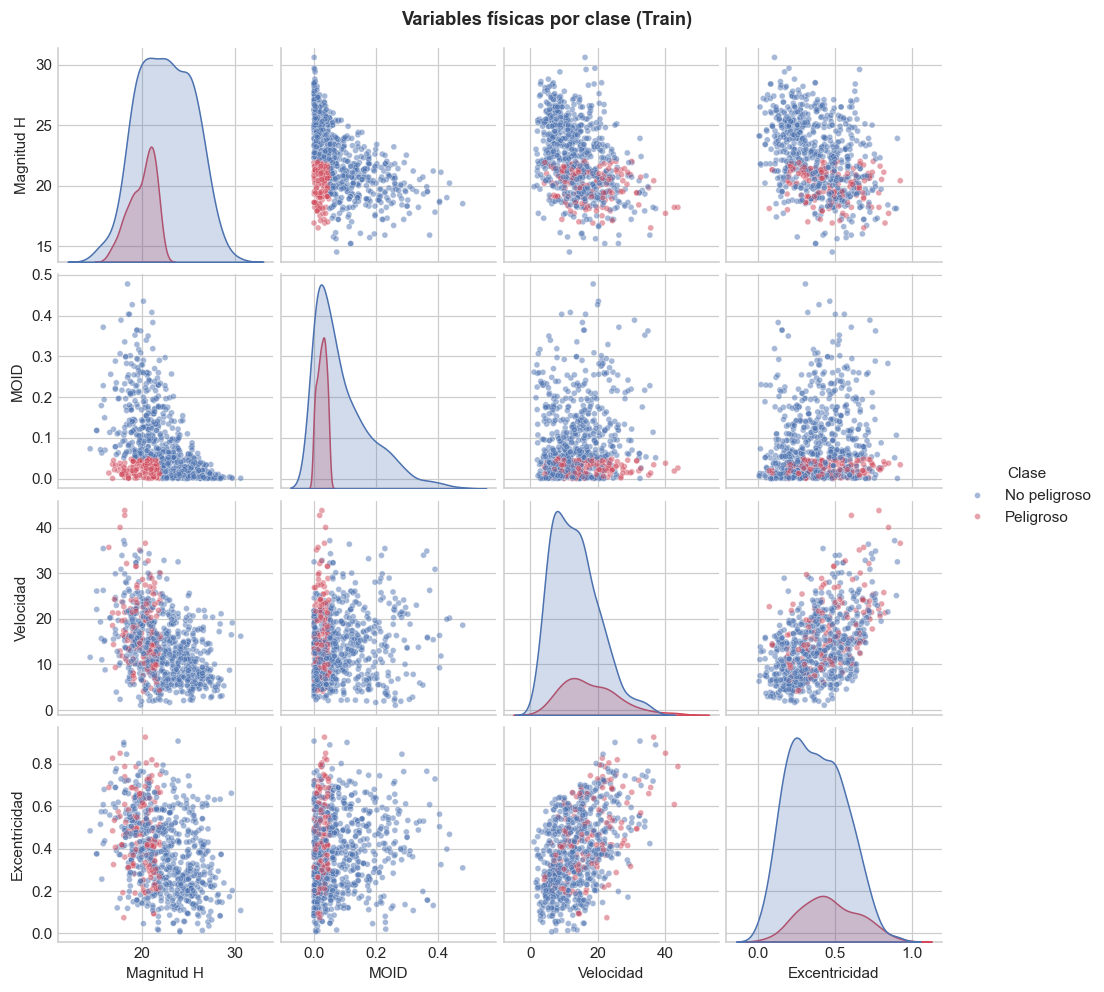

In [7]:
# 3.1 Pairplot de variables físicas (muestra de Train)
cortos = {
    'Absolute Magnitude': 'Magnitud H',
    'Minimum Orbit Intersection': 'MOID',
    'Relative Velocity km per sec': 'Velocidad',
    'Eccentricity': 'Excentricidad'
}
sample_eda = (df.iloc[idx_train].sample(min(800, len(idx_train)), random_state=SEED)
              .rename(columns=cortos)
              .assign(Clase=lambda d: d[TARGET].map(ETIQUETAS_CLASE)))

g_pair = sns.pairplot(
    sample_eda[list(cortos.values()) + ['Clase']],
    hue='Clase', hue_order=list(PALETA_ETIQUETAS), height=2.2, diag_kind='kde',
    palette=PALETA_ETIQUETAS,
    plot_kws={'alpha': 0.5, 's': 15}
)
g_pair.fig.suptitle('Variables físicas por clase (Train)', y=1.02, fontweight='bold')
plt.show()

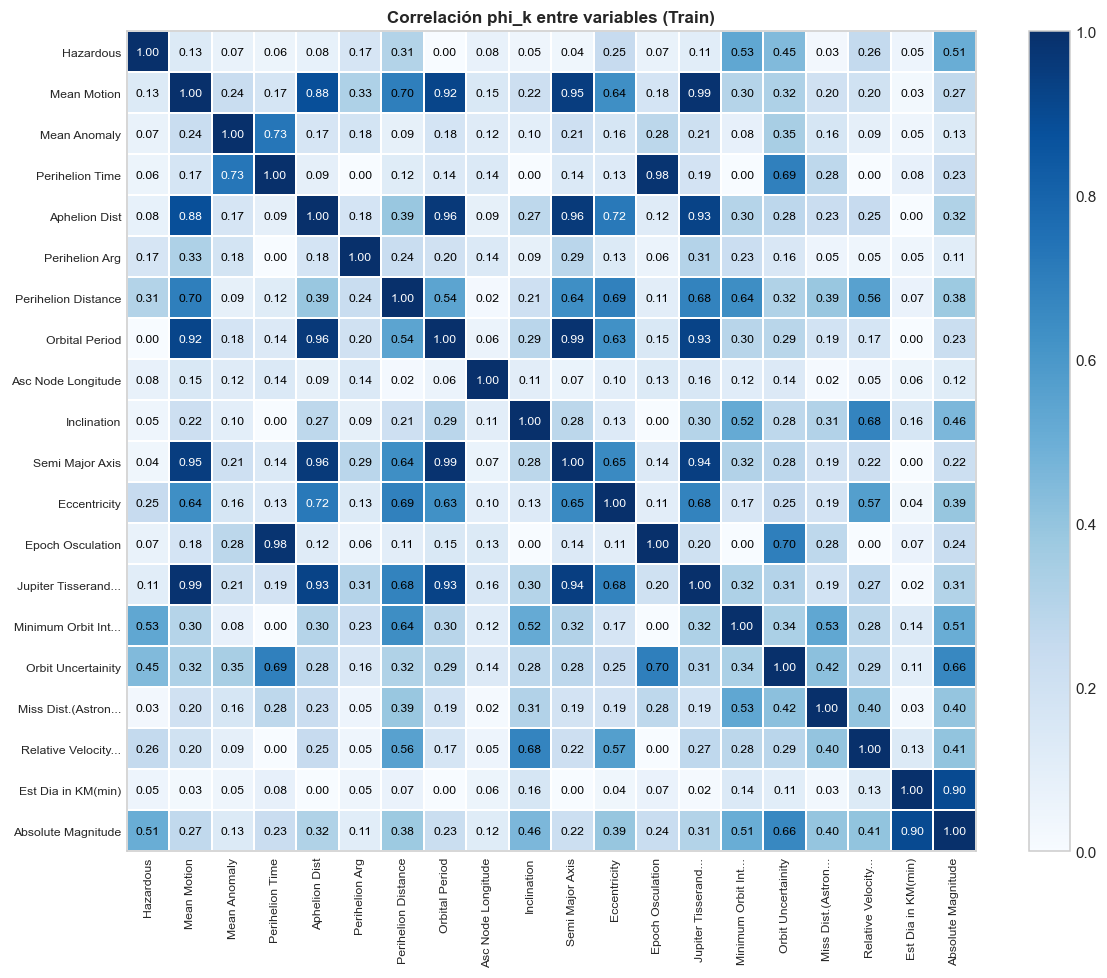

Las 6 variables más asociadas con Hazardous (phi_k):


Minimum Orbit Intersection      0.534
Absolute Magnitude              0.507
Orbit Uncertainity              0.446
Perihelion Distance             0.310
Relative Velocity km per sec    0.256
Eccentricity                    0.247
Name: Hazardous, dtype: float64

In [8]:
# 3.1 Matriz de correlación phi_k
df_phik = df.iloc[idx_train].copy()
df_phik[TARGET] = df_phik[TARGET].astype(str)
phik_matrix = df_phik.phik_matrix(interval_cols=df_phik.select_dtypes('number').columns.tolist())

# plot_correlation_matrix crea su propia figura
plot_correlation_matrix(
    phik_matrix.values, x_labels=phik_matrix.columns, y_labels=phik_matrix.index,
    vmin=0, vmax=1, color_map='Blues', title='Correlación phi_k entre variables (Train)',
    fontsize_factor=0.8, figsize=(11, 9)
)
plt.tight_layout()
plt.show()

print('Las 6 variables más asociadas con Hazardous (phi_k):')
display(phik_matrix[TARGET].drop(TARGET).sort_values(ascending=False).head(6).round(3))

<a id="s3-2"></a>
### 3.2 Escalado y normalización

Comparamos cuatro opciones:

- Sin escalar.
- `StandardScaler`: media 0 y desviación estándar 1.
- `MinMaxScaler`: todo en el rango [0, 1].
- `RobustScaler`: usa la mediana y el rango intercuartílico, así que le afectan menos los valores atípicos.

Las probamos con los tres modelos que dependen de la escala de las variables (regresión logística, SVM con kernel RBF y k-NN), con validación cruzada agrupada de 5 folds en el escenario B. Nos quedamos con el escalador de mayor PR-AUC promedio y lo usamos en el resto del notebook.

In [9]:
# 3.2 Comparación de escaladores (escenario B)
X_train_B = X_esc(ESCENARIO_DESPLIEGUE, idx_train)

scalers_dict = {
    'Sin escalar': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

scaling_models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, class_weight='balanced', random_state=SEED),
    'k-NN (k=15)': KNeighborsClassifier(n_neighbors=15)
}

scaling_summary = []
for s_name, scaler_obj in scalers_dict.items():
    for m_name, model_obj in scaling_models.items():
        pipe = hacer_pipeline(clone(model_obj), scaler_obj)
        sc = cross_validate(pipe, X_train_B, y_train_arr, groups=g_train_arr, cv=cv_5f,
                            scoring={k: SCORING[k] for k in ['f1', 'pr_auc', 'recall']}, n_jobs=-1)
        scaling_summary.append({'Escalador': s_name, 'Modelo': m_name, **resumir_cv(sc, ['f1', 'pr_auc', 'recall'])})

df_scaling_res = pd.DataFrame(scaling_summary)
display(df_scaling_res.pivot(index='Escalador', columns='Modelo', values=['f1', 'pr_auc']).round(4))

ranking_escaladores = (df_scaling_res[df_scaling_res['Escalador'] != 'Sin escalar']
                       .groupby('Escalador')['pr_auc'].mean().sort_values(ascending=False))
NOMBRE_ESCALADOR = ranking_escaladores.index[0]
ESCALADOR = scalers_dict[NOMBRE_ESCALADOR]
sin_escalar = df_scaling_res[df_scaling_res['Escalador'] == 'Sin escalar']['pr_auc'].mean()
print(f'PR-AUC medio por escalador (3 modelos): {ranking_escaladores.round(4).to_dict()} | Sin escalar: {sin_escalar:.4f}')
print(f'Escalador elegido para el resto del notebook: {NOMBRE_ESCALADOR}')

f1                                    pr_auc  \
Modelo         Logistic Regression SVM (RBF) k-NN (k=15) Logistic Regression   
Escalador                                                                      
MinMaxScaler                0.5192    0.5297      0.2825              0.4324   
RobustScaler                0.5358    0.2866      0.2433              0.4686   
Sin escalar                 0.4844    0.1243      0.0444              0.4128   
StandardScaler              0.5375    0.5577      0.2818              0.4680   

                                      
Modelo         SVM (RBF) k-NN (k=15)  
Escalador                             
MinMaxScaler      0.4466      0.3849  
RobustScaler      0.2991      0.4163  
Sin escalar       0.1663      0.1892  
StandardScaler    0.4717      0.4422

PR-AUC medio por escalador (3 modelos): {'StandardScaler': 0.4606, 'MinMaxScaler': 0.4213, 'RobustScaler': 0.3946} | Sin escalar: 0.2561
Escalador elegido para el resto del notebook: StandardScaler


<a id="s3-3"></a>
### 3.3 Reducción de dimensionalidad con PCA

En el escenario B, ajustando PCA solo con los datos de entrenamiento:

1. Curva de varianza explicada acumulada, para saber cuántas componentes hacen falta para llegar al 95%.
2. Proyección en 2 componentes, coloreada por clase.
3. Comparación con validación cruzada de cuatro representaciones (datos crudos, escalados, escalados + PCA 95% y escalados + PCA 2D) con un modelo lineal (regresión logística) y uno no lineal (Random Forest).

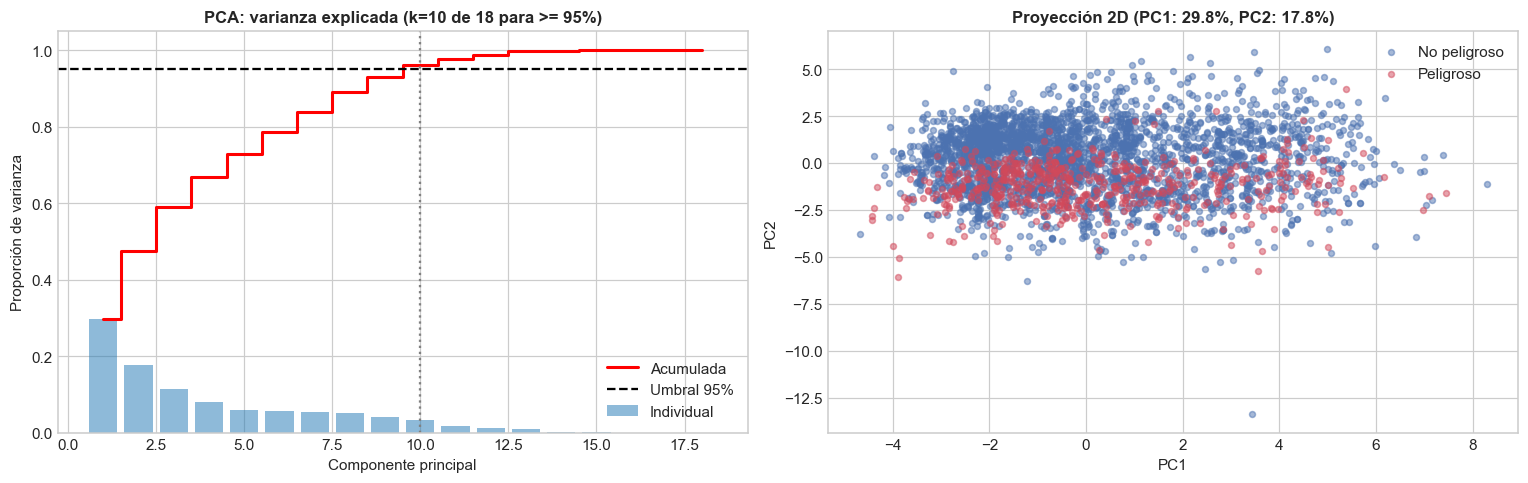

Se requieren 10 componentes para retener >= 95% de la varianza (96.17%).


f1               pr_auc              roc_auc  \
Modelo                      LogReg RandomForest  LogReg RandomForest  LogReg   
Representación                                                                 
Crudo (sin escalar)         0.4844       0.5671  0.4128       0.7078  0.8203   
Escalado (StandardScaler)   0.5375       0.5669  0.4680       0.7112  0.8568   
Escalado + PCA (>=95% var)  0.4892       0.3122  0.4127       0.4914  0.8229   
Escalado + PCA (2D)         0.4184       0.2849  0.2898       0.3359  0.7495   

                                         
Modelo                     RandomForest  
Representación                           
Crudo (sin escalar)              0.9294  
Escalado (StandardScaler)        0.9297  
Escalado + PCA (>=95% var)       0.8498  
Escalado + PCA (2D)              0.7503

In [10]:
# 3.3 PCA ajustado con Train (escenario B)
pipe_std = hacer_pipeline('passthrough', ESCALADOR)
X_tr_std = pipe_std.fit_transform(X_train_B)

pca_full = PCA(random_state=SEED).fit(X_tr_std)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
K95 = int(np.searchsorted(cum_var, 0.95) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# Curva de varianza
comps = np.arange(1, len(cum_var) + 1)
axes[0].bar(comps, pca_full.explained_variance_ratio_, alpha=0.5, label='Individual')
axes[0].step(comps, cum_var, where='mid', color='red', lw=2, label='Acumulada')
axes[0].axhline(0.95, color='black', ls='--', label='Umbral 95%')
axes[0].axvline(K95, color='gray', ls=':')
axes[0].set_title(f'PCA: varianza explicada (k={K95} de {len(comps)} para >= 95%)')
axes[0].set_xlabel('Componente principal'); axes[0].set_ylabel('Proporción de varianza'); axes[0].legend()

# Scatter 2D
pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr_std)
Z2 = pca2.transform(X_tr_std)
for clase, etiqueta in [(0, 'No peligroso'), (1, 'Peligroso')]:
    m = y_train_arr == clase
    axes[1].scatter(Z2[m, 0], Z2[m, 1], c=COLORES_CLASE[clase], alpha=0.5, s=15, label=etiqueta)
axes[1].set_title(f'Proyección 2D (PC1: {pca2.explained_variance_ratio_[0]:.1%}, PC2: {pca2.explained_variance_ratio_[1]:.1%})')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].legend()

plt.tight_layout()
plt.show()
print(f'Se requieren {K95} componentes para retener >= 95% de la varianza ({cum_var[K95-1]:.2%}).')

# Comparación: crudo vs escalado vs escalado + PCA
pca_scen = {
    'Crudo (sin escalar)': (None, None),
    f'Escalado ({NOMBRE_ESCALADOR})': (ESCALADOR, None),
    'Escalado + PCA (>=95% var)': (ESCALADOR, PCA(n_components=0.95, random_state=SEED)),
    'Escalado + PCA (2D)': (ESCALADOR, PCA(n_components=2, random_state=SEED))
}
modelos_pca = {
    'LogReg': LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1)
}
pca_eval_rows = []
for p_name, (esc_obj, pca_obj) in pca_scen.items():
    for m_name, m_obj in modelos_pca.items():
        pasos = [('imputer', SimpleImputer(strategy='median'))]
        if esc_obj is not None:
            pasos.append(('scaler', clone(esc_obj)))
        if pca_obj is not None:
            pasos.append(('pca', clone(pca_obj)))
        pasos.append(('clf', clone(m_obj)))
        res_p = cross_validate(Pipeline(pasos), X_train_B, y_train_arr, groups=g_train_arr, cv=cv_5f,
                               scoring={k: SCORING[k] for k in ['f1', 'pr_auc', 'roc_auc']}, n_jobs=-1)
        pca_eval_rows.append({'Representación': p_name, 'Modelo': m_name, **resumir_cv(res_p, ['f1', 'pr_auc', 'roc_auc'])})

df_pca_eval = pd.DataFrame(pca_eval_rows)
display(df_pca_eval.pivot(index='Representación', columns='Modelo', values=['f1', 'pr_auc', 'roc_auc'])
        .reindex(list(pca_scen)).round(4))

<a id="s3-4"></a>
### 3.4 Selección de variables

Comparamos tres familias de métodos en el escenario B:

1. **Filtro:** quitamos las variables muy correlacionadas entre sí ($|r| > 0.85$) y nos quedamos con las 10 de mayor información mutua con la clase (`SelectKBest(mutual_info_classif)`).
2. **Wrapper:** `RFECV` con Random Forest. Quita variables de una en una y mide cada paso con validación cruzada agrupada.
3. **Embedded:** las importancias del Random Forest (`SelectFromModel`, umbral = la media) y una regresión logística con penalización $L_1$, que deja en cero los coeficientes de las variables que no aportan.

En esta celda cada método se ajusta con todo el conjunto de entrenamiento, solo para ver qué variables escoge. La comparación justa está en [3.6](#s3-6).

Eliminadas por colinealidad (|r| > 0.85): ['Semi Major Axis', 'Orbital Period', 'Aphelion Dist', 'Perihelion Time', 'Mean Motion']


Filtro (|r|+MI top-10)       (10): ['Absolute Magnitude', 'Est Dia in KM(min)', 'Orbit Uncertainity', 'Jupiter Tisserand Invariant', 'Eccentricity', 'Inclination', 'Asc Node Longitude', 'Perihelion Distance', 'Perihelion Arg', 'Mean Anomaly']
Wrapper (RFECV)              ( 9): ['Absolute Magnitude', 'Est Dia in KM(min)', 'Miss Dist.(Astronomical)', 'Orbit Uncertainity', 'Eccentricity', 'Inclination', 'Perihelion Distance', 'Perihelion Arg', 'Mean Motion']
Embedded (RF importancias)   ( 6): ['Absolute Magnitude', 'Est Dia in KM(min)', 'Orbit Uncertainity', 'Inclination', 'Perihelion Distance', 'Perihelion Arg']
Embedded (L1 LogReg)         (13): ['Absolute Magnitude', 'Est Dia in KM(min)', 'Relative Velocity km per sec', 'Miss Dist.(Astronomical)', 'Orbit Uncertainity', 'Eccentricity', 'Inclination', 'Asc Node Longitude', 'Perihelion Distance', 'Aphelion Dist', 'Perihelion Time', 'Mean Anomaly', 'Mean Motion']


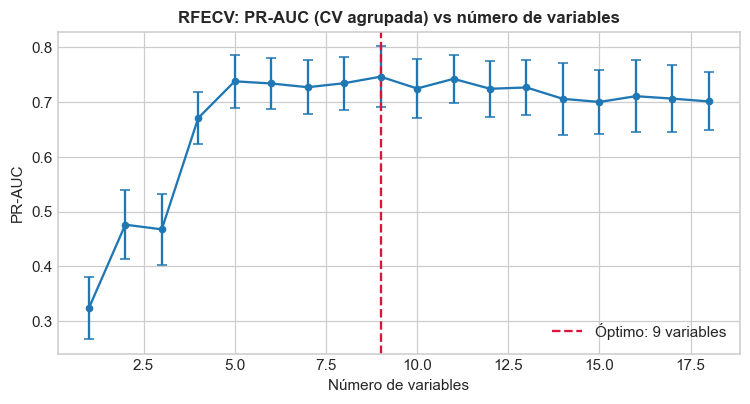

In [11]:
# 3.4 Selección de variables (escenario B): qué escoge cada método con todo Train
from functools import partial


class FiltroCorrelacion(BaseEstimator, TransformerMixin):
    """Filtro no supervisado: elimina cada variable con |r| > umbral respecto a alguna variable anterior."""

    def __init__(self, umbral: float = 0.85) -> None:
        self.umbral = umbral

    def fit(self, X: Any, y: Any = None) -> 'FiltroCorrelacion':
        corr = np.abs(pd.DataFrame(np.asarray(X, dtype=float)).corr().to_numpy())
        self.support_ = ~(np.triu(corr, k=1) > self.umbral).any(axis=0)
        self.n_features_in_ = corr.shape[0]
        return self

    def transform(self, X: Any) -> np.ndarray:
        return np.asarray(X, dtype=float)[:, self.support_]

    def get_support(self) -> np.ndarray:
        return self.support_


class SeleccionFija(BaseEstimator, TransformerMixin):
    """Selecciona un subconjunto fijo de columnas (por posición) dentro de un Pipeline."""

    def __init__(self, indices: tuple[int, ...] = ()) -> None:
        self.indices = indices

    def fit(self, X: Any, y: Any = None) -> 'SeleccionFija':
        return self

    def transform(self, X: Any) -> np.ndarray:
        return np.asarray(X, dtype=float)[:, list(self.indices)]


COLS_B = list(X_train_B.columns)
mi_score = partial(mutual_info_classif, random_state=SEED)
subconjuntos: dict[str, list[str]] = {}

# 1. Filtro: correlación |r| > 0.85 + información mutua (top-10)
filtro_corr = FiltroCorrelacion(0.85).fit(X_train_B)
cols_corr = [c for c, keep in zip(COLS_B, filtro_corr.get_support()) if keep]
print(f'Eliminadas por colinealidad (|r| > 0.85): {[c for c in COLS_B if c not in cols_corr]}')
kbest = SelectKBest(mi_score, k=min(10, len(cols_corr))).fit(X_train_B[cols_corr], y_train_arr)
subconjuntos['Filtro (|r|+MI top-10)'] = [c for c, keep in zip(cols_corr, kbest.get_support()) if keep]

# 2. Wrapper: RFECV con validación cruzada agrupada
rfecv = RFECV(
    estimator=RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=1),
    step=1, cv=cv_5f, scoring='average_precision', min_features_to_select=1, n_jobs=-1
)
rfecv.fit(X_train_B, y_train_arr, groups=g_train_arr)
subconjuntos['Wrapper (RFECV)'] = [c for c, keep in zip(COLS_B, rfecv.support_) if keep]

# 3a. Embedded: importancias de Random Forest (umbral = media)
sfm_rf = SelectFromModel(RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1),
                         threshold='mean').fit(X_train_B, y_train_arr)
subconjuntos['Embedded (RF importancias)'] = [c for c, keep in zip(COLS_B, sfm_rf.get_support()) if keep]

# 3b. Embedded: regularización L1 (requiere escalado previo)
L1_SELECTOR = SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=0.1,
                                                 class_weight='balanced', random_state=SEED))
pipe_l1 = Pipeline([('scaler', clone(ESCALADOR)), ('sel', clone(L1_SELECTOR))]).fit(X_train_B, y_train_arr)
subconjuntos['Embedded (L1 LogReg)'] = [c for c, keep in zip(COLS_B, pipe_l1.named_steps['sel'].get_support()) if keep]

for metodo, cols in subconjuntos.items():
    print(f'{metodo:28s} ({len(cols):2d}): {cols}')

# Curva del wrapper RFECV
plt.figure(figsize=(8, 3.8))
n_feats = np.arange(1, len(rfecv.cv_results_['mean_test_score']) + 1)
plt.errorbar(n_feats, rfecv.cv_results_['mean_test_score'], yerr=rfecv.cv_results_['std_test_score'], marker='o', ms=4, capsize=3)
plt.axvline(rfecv.n_features_, color='crimson', ls='--', label=f'Óptimo: {rfecv.n_features_} variables')
plt.title('RFECV: PR-AUC (CV agrupada) vs número de variables')
plt.xlabel('Número de variables'); plt.ylabel('PR-AUC'); plt.legend()
plt.show()

<a id="s3-5"></a>
### 3.5 SHAP: qué variables pesan más

SHAP reparte la predicción de cada asteroide entre sus variables: dice cuánto subió o bajó cada una la probabilidad de ser peligroso. Usamos `shap.TreeExplainer` sobre un Random Forest, en dos escenarios para compararlos:

- **Gráfico beeswarm** del escenario A (con MOID) y del escenario B (sin MOID). Cada punto es un asteroide y el color es el valor de la variable (rojo = alto, azul = bajo).
- **Ranking** por importancia media, $E[|\text{SHAP}|]$.

Las 5 variables más importantes del escenario B entran como un método de selección más en la comparación de [3.6](#s3-6).

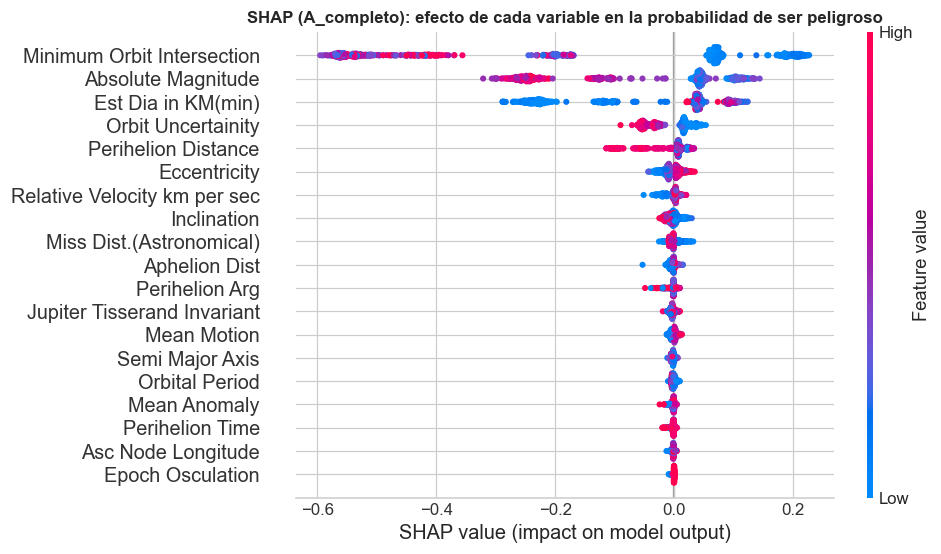

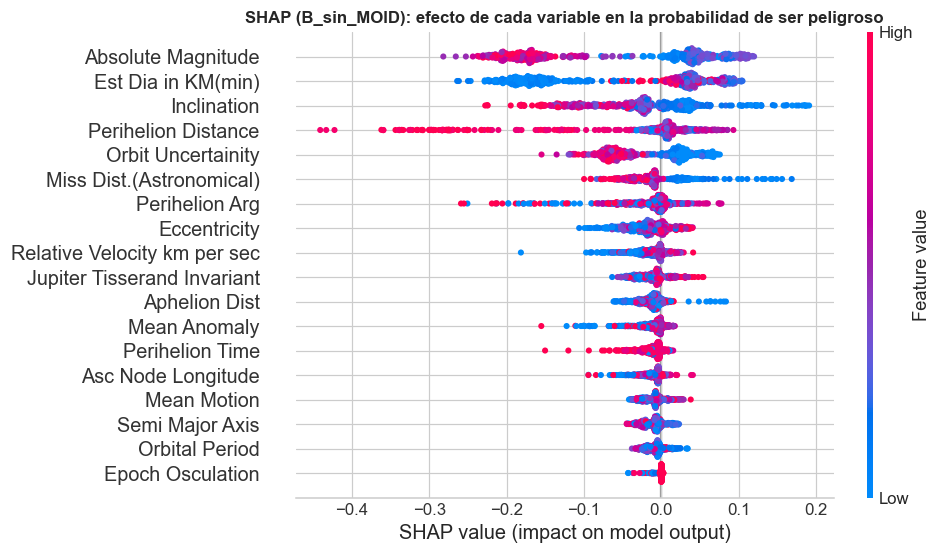

Ranking E[|SHAP|] (top 8) por escenario:


,A_completo,B_sin_MOID
#1,Minimum Orbit Intersection (0.273),Absolute Magnitude (0.109)
#2,Absolute Magnitude (0.133),Est Dia in KM(min) (0.101)
#3,Est Dia in KM(min) (0.123),Inclination (0.055)
#4,Orbit Uncertainity (0.033),Perihelion Distance (0.054)
#5,Perihelion Distance (0.022),Orbit Uncertainity (0.047)
#6,Eccentricity (0.012),Miss Dist.(Astronomical) (0.028)
#7,Relative Velocity km per sec (0.008),Perihelion Arg (0.027)
#8,Inclination (0.007),Eccentricity (0.023)


Top 5 rasgos SHAP en B_sin_MOID: ['Absolute Magnitude', 'Est Dia in KM(min)', 'Inclination', 'Perihelion Distance', 'Orbit Uncertainity']


In [12]:
# 3.5 SHAP: escenario A (con MOID) vs escenario B (sin MOID)
K_SHAP = 5
rankings_shap: dict[str, pd.Series] = {}

for esc in ['A_completo', ESCENARIO_DESPLIEGUE]:
    X_tr_esc = X_esc(esc, idx_train)
    rf_shap = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1).fit(X_tr_esc, y_train_arr)
    sample_shap = X_tr_esc.sample(min(600, len(X_tr_esc)), random_state=SEED)
    shap_vals = shap.TreeExplainer(rf_shap).shap_values(sample_shap, check_additivity=False)
    sv_pos = shap_vals[1] if isinstance(shap_vals, list) else (shap_vals[:, :, 1] if np.ndim(shap_vals) == 3 else shap_vals)

    shap.summary_plot(sv_pos, sample_shap, show=False, plot_size=(9, 5))
    plt.title(f'SHAP ({esc}): efecto de cada variable en la probabilidad de ser peligroso', fontweight='bold')
    plt.show()
    rankings_shap[esc] = pd.Series(np.abs(sv_pos).mean(axis=0), index=X_tr_esc.columns).sort_values(ascending=False)

tabla_shap = pd.DataFrame({
    esc: [f'{c} ({v:.3f})' for c, v in serie.head(8).items()] for esc, serie in rankings_shap.items()
}, index=[f'#{i}' for i in range(1, 9)])
print('Ranking E[|SHAP|] (top 8) por escenario:')
display(tabla_shap)

subconjuntos[f'SHAP (top-{K_SHAP})'] = rankings_shap[ESCENARIO_DESPLIEGUE].head(K_SHAP).index.tolist()
print(f'Top {K_SHAP} rasgos SHAP en {ESCENARIO_DESPLIEGUE}: {subconjuntos[f"SHAP (top-{K_SHAP})"]}')

<a id="s3-6"></a>
### 3.6 Comparación de los métodos de selección

Primero, una tabla con las variables que escogió cada método y cuántos votos recibe cada variable. Después medimos cada método **dentro del Pipeline**: el selector se vuelve a ajustar en cada fold, así que nunca ve los datos con los que se evalúa. El clasificador es siempre un Random Forest.

In [13]:
# 3.6 Variables escogidas por cada método y evaluación de cada uno dentro del Pipeline
tabla_sel = pd.DataFrame({m: ['✔' if c in cols else '' for c in COLS_B] for m, cols in subconjuntos.items()}, index=COLS_B)
tabla_sel['Votos'] = (tabla_sel == '✔').sum(axis=1)
tabla_sel = tabla_sel.sort_values('Votos', ascending=False)
tabla_sel.loc['TOTAL seleccionadas'] = [len(subconjuntos[m]) for m in subconjuntos] + ['']
print('Variables escogidas por cada método (ajustados con Train, escenario B):')
display(tabla_sel)

rf_sel = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=1)
idx_shap = tuple(COLS_B.index(c) for c in subconjuntos[f'SHAP (top-{K_SHAP})'])
selectores: dict[str, list[tuple[str, Any]]] = {
    'Todas las variables': [],
    'Filtro (|r|+MI top-10)': [('corr', FiltroCorrelacion(0.85)), ('kbest', SelectKBest(mi_score, k=10))],
    'Wrapper (RFE, k de RFECV)': [('rfe', RFE(RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=1),
                                            n_features_to_select=rfecv.n_features_))],
    'Embedded (RF importancias)': [('sfm', SelectFromModel(clone(rf_sel), threshold='mean'))],
    'Embedded (L1 LogReg)': [('scaler', clone(ESCALADOR)), ('sfm', clone(L1_SELECTOR))],
    f'SHAP (top-{K_SHAP}, lista fija)': [('cols', SeleccionFija(idx_shap))]
}

filas_sel = []
for nombre, pasos in selectores.items():
    pipe_sel = Pipeline([('imputer', SimpleImputer(strategy='median'))] + pasos + [('clf', clone(rf_sel))])
    res_s = cross_validate(pipe_sel, X_train_B, y_train_arr, groups=g_train_arr, cv=cv_5f,
                           scoring={k: SCORING[k] for k in ['f1', 'f2', 'pr_auc', 'recall']}, n_jobs=-1)
    filas_sel.append({'Método': nombre, **resumir_cv(res_s, ['f1', 'f2', 'pr_auc', 'recall'])})

df_sel_eval = pd.DataFrame(filas_sel).set_index('Método').sort_values('pr_auc', ascending=False)
display(df_sel_eval.round(4))
print('Notas: (1) los selectores se vuelven a ajustar en cada fold; (2) el número de variables del wrapper (k) y la lista '
      'SHAP se escogieron con todo Train, así que esas dos filas son un poco optimistas.')

Variables escogidas por cada método (ajustados con Train, escenario B):


,Filtro (|r|+MI top-10),Wrapper (RFECV),Embedded (RF importancias),Embedded (L1 LogReg),SHAP (top-5),Votos
Absolute Magnitude,✔,✔,✔,✔,✔,5
Est Dia in KM(min),✔,✔,✔,✔,✔,5
Orbit Uncertainity,✔,✔,✔,✔,✔,5
Inclination,✔,✔,✔,✔,✔,5
Perihelion Distance,✔,✔,✔,✔,✔,5
Eccentricity,✔,✔,,✔,,3
Perihelion Arg,✔,✔,✔,,,3
Asc Node Longitude,✔,,,✔,,2
Mean Motion,,✔,,✔,,2
Miss Dist.(Astronomical),,✔,,✔,,2


,f1,f1_std,f2,f2_std,pr_auc,pr_auc_std,recall,recall_std
Método,,,,,,,,
"Wrapper (RFE, k de RFECV)",0.6047,0.0298,0.5406,0.0228,0.7483,0.0599,0.5052,0.0224
Filtro (|r|+MI top-10),0.5626,0.0584,0.4912,0.0605,0.7100,0.0526,0.4534,0.0622
Todas las variables,0.5671,0.0435,0.4950,0.0504,0.7078,0.0499,0.4569,0.0540
Embedded (L1 LogReg),0.5378,0.0444,0.4690,0.0504,0.6888,0.0373,0.4327,0.0532
Embedded (RF importancias),0.5388,0.0909,0.4892,0.0667,0.6460,0.1405,0.4626,0.0572
"SHAP (top-5, lista fija)",0.5071,0.0215,0.4663,0.0261,0.6333,0.0413,0.4435,0.0340


Notas: (1) los selectores se vuelven a ajustar en cada fold; (2) el número de variables del wrapper (k) y la lista SHAP se escogieron con todo Train, así que esas dos filas son un poco optimistas.


<a id="s3-7"></a>
### 3.7 ¿Se puede calcular el MOID desde la órbita?

El escenario B le quita al modelo la columna `Minimum Orbit Intersection`, pero el MOID no es un dato independiente: es una distancia geométrica que sale de la órbita. Lo comprobamos de dos formas:

1. **Cálculo directo.** Recorremos la órbita de cada asteroide en 720 puntos (con el semieje mayor, la excentricidad, la inclinación y el argumento del perihelio) y medimos la distancia mínima a un círculo de 1 UA en el plano de la Tierra. Comparamos ese MOID calculado con el del dataset, y vemos si cae del mismo lado del umbral de 0.05 UA.
2. **Variables de geometría orbital.** La órbita del asteroide cruza el plano de la órbita de la Tierra en dos puntos, los nodos; si en alguno de ellos el asteroide está a casi 1 UA del Sol, las dos órbitas casi se tocan. Calculamos seis variables con esa idea:

| Variable | Qué es |
| :--- | :--- |
| `Dist. nodo asc. (UA)`, `Dist. nodo desc. (UA)` | Distancia al Sol en cada nodo: $r = \frac{a(1-e^2)}{1 \pm e\cos\omega}$ |
| `Nodo más cercano a 1 UA` | $\min(|r_{asc} - 1|, |r_{desc} - 1|)$ |
| `Cruza 1 UA` | 1 si el perihelio está dentro de la órbita de la Tierra y el afelio fuera ($q \le 1 \le Q$) |
| `Dist. q-Q a 1 UA` | 0 si cruza; si no, qué tan lejos queda de 1 UA el punto más cercano |
| `q - 1 UA` | Perihelio menos 1 UA |

Con validación cruzada agrupada comparamos el mismo modelo en el escenario B, en el B con estas seis variables y en el A (con el MOID). Si el B con geometría orbital llega casi al nivel del A, el modelo está rearmando la regla de la NASA a partir de la órbita.

Esta sección es un análisis: ni el MOID calculado ni las seis variables entran al modelo del escenario B que se evalúa y se despliega más adelante.

MOID calculado vs MOID del dataset: correlación 0.9964 | error mediano 0.0046 UA | mismo lado de 0.05 UA en el 97.1% de las filas


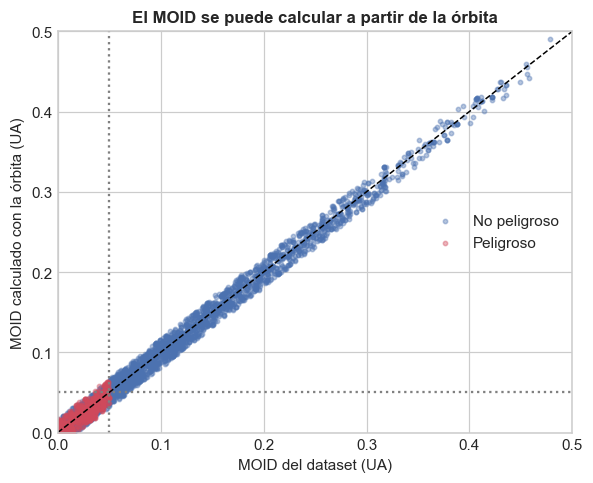

,Modelo,pr_auc,pr_auc_std,f2,f2_std,recall,recall_std
Variables,,,,,,,
Escenario B,HistGradientBoosting,0.8220,0.0274,0.7606,0.0249,0.7803,0.0389
Escenario B + geometría orbital,HistGradientBoosting,0.9729,0.0098,0.9101,0.0222,0.9046,0.0265
Escenario A (con MOID),HistGradientBoosting,0.9968,0.0038,0.9701,0.0240,0.9673,0.0288


In [14]:
# 3.7 ¿Se puede calcular el MOID desde la órbita? (análisis: nada de esto entra al modelo desplegado)
def moid_desde_orbita(d: pd.DataFrame, n: int = 720) -> np.ndarray:
    """Distancia mínima entre la órbita (en n puntos) y un círculo de 1 UA en la eclíptica."""
    a, e, i, w = (d[c].to_numpy(float)[:, None] for c in ['Semi Major Axis', 'Eccentricity', 'Inclination', 'Perihelion Arg'])
    nu = np.linspace(0, 2 * np.pi, n, endpoint=False)[None, :]       # anomalía verdadera
    r = a * (1 - e ** 2) / (1 + e * np.cos(nu))
    u, inc = nu + np.radians(w), np.radians(i)
    x, y_orb, z = r * np.cos(u), r * np.sin(u) * np.cos(inc), r * np.sin(u) * np.sin(inc)
    return np.sqrt((np.sqrt(x ** 2 + y_orb ** 2) - 1) ** 2 + z ** 2).min(axis=1)


def geometria_orbital(d: pd.DataFrame) -> pd.DataFrame:
    """Seis variables de la geometría de la órbita frente a la de la Tierra (un círculo de 1 UA en la eclíptica)."""
    a, e = d['Semi Major Axis'], d['Eccentricity']
    q, Q = d['Perihelion Distance'], d['Aphelion Dist']
    p = a * (1 - e ** 2)                                        # semilado recto
    cos_w = np.cos(np.radians(d['Perihelion Arg']))
    r_asc, r_desc = p / (1 + e * cos_w), p / (1 - e * cos_w)    # distancia al Sol en cada nodo
    cruza = ((q <= 1) & (Q >= 1)).astype(float)
    return pd.DataFrame({
        'Dist. nodo asc. (UA)': r_asc,
        'Dist. nodo desc. (UA)': r_desc,
        'Nodo más cercano a 1 UA': np.minimum((r_asc - 1).abs(), (r_desc - 1).abs()),
        'Cruza 1 UA': cruza,
        'Dist. q-Q a 1 UA': np.where(cruza == 1, 0.0, np.minimum((q - 1).abs(), (Q - 1).abs())),
        'q - 1 UA': q - 1,
    }, index=d.index)


# 1. MOID calculado frente al MOID del dataset
moid_calc = moid_desde_orbita(X_all)
moid_real = X_all['Minimum Orbit Intersection'].to_numpy()
CORR_MOID = float(np.corrcoef(moid_calc, moid_real)[0, 1])
ACUERDO_MOID = float(((moid_calc <= 0.05) == (moid_real <= 0.05)).mean())
print(f'MOID calculado vs MOID del dataset: correlación {CORR_MOID:.4f} | error mediano {np.median(np.abs(moid_calc - moid_real)):.4f} UA | '
      f'mismo lado de 0.05 UA en el {ACUERDO_MOID:.1%} de las filas')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for clase in (0, 1):
    m = y == clase
    ax.scatter(moid_real[m], moid_calc[m], s=8, alpha=0.4, c=COLORES_CLASE[clase], label=ETIQUETAS_CLASE[clase])
ax.plot([0, 0.5], [0, 0.5], color='black', lw=1, ls='--')
ax.axvline(0.05, color='gray', ls=':'); ax.axhline(0.05, color='gray', ls=':')
ax.set_xlim(0, 0.5); ax.set_ylim(0, 0.5)
ax.set_xlabel('MOID del dataset (UA)'); ax.set_ylabel('MOID calculado con la órbita (UA)')
ax.set_title('El MOID se puede calcular a partir de la órbita'); ax.legend()
plt.tight_layout(); plt.show()

# 2. Mismo modelo y mismos folds: escenario B, B + geometría orbital y A
X_geo = pd.concat([X_all, geometria_orbital(X_all)], axis=1)
VARIABLES_GEOMETRIA = list(geometria_orbital(X_all.head(1)).columns)
modelo_geo = hacer_pipeline(HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED))
filas_geo = []
for variables, cols in [('Escenario B', columnas_escenario(ESCENARIO_DESPLIEGUE)),
                        ('Escenario B + geometría orbital', columnas_escenario(ESCENARIO_DESPLIEGUE) + VARIABLES_GEOMETRIA),
                        ('Escenario A (con MOID)', columnas_escenario('A_completo'))]:
    res = cross_validate(clone(modelo_geo), X_geo.iloc[idx_train][cols], y_train_arr, groups=g_train_arr, cv=cv_5f,
                         scoring={k: SCORING[k] for k in ['pr_auc', 'f2', 'recall']}, n_jobs=-1)
    filas_geo.append({'Variables': variables, 'Modelo': 'HistGradientBoosting', **resumir_cv(res, ['pr_auc', 'f2', 'recall'])})
df_geo = pd.DataFrame(filas_geo).set_index('Variables')
display(df_geo.round(4))

<a id="s4"></a>
## 4. Modelado (Configure & Build)

<a id="s4-1"></a>
### 4.1 Sesgo y varianza con k-NN

Para empezar miramos el sobreajuste en un caso sencillo: k-NN con $k$ de 1 a 41, comparando el PR-AUC en entrenamiento y en validación cruzada (escenario B). Con $k$ pequeño el modelo memoriza; con $k$ muy grande se vuelve demasiado simple.

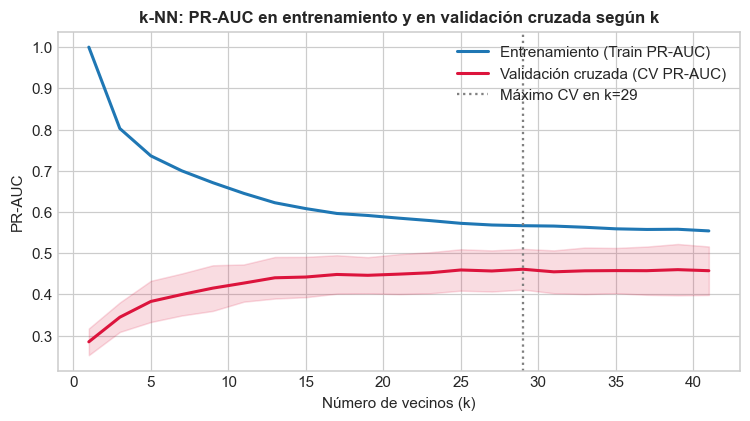

k pequeño: varianza alta (Train cerca de 1.0 y CV bajo). k grande: sesgo alto (bajan las dos curvas).


In [15]:
# 4.1 Curva de sesgo y varianza para k-NN (escenario B)
from threadpoolctl import threadpool_limits

k_range = np.arange(1, 42, 2)
pr_train_k, pr_cv_k, pr_cv_k_std = [], [], []

# Un solo hilo de OpenMP/BLAS: con datos tan pequeños es más rápido y evita bloqueos de k-NN en Windows
with threadpool_limits(limits=1):
    for k in k_range:
        tr_scores, te_scores = [], []
        for tr_i, te_i in cv_5f.split(X_train_B, y_train_arr, g_train_arr):
            pipe_k = hacer_pipeline(KNeighborsClassifier(n_neighbors=k), ESCALADOR)
            pipe_k.fit(X_train_B.iloc[tr_i], y_train_arr[tr_i])
            tr_scores.append(average_precision_score(y_train_arr[tr_i], pipe_k.predict_proba(X_train_B.iloc[tr_i])[:, 1]))
            te_scores.append(average_precision_score(y_train_arr[te_i], pipe_k.predict_proba(X_train_B.iloc[te_i])[:, 1]))
        pr_train_k.append(np.mean(tr_scores))
        pr_cv_k.append(np.mean(te_scores))
        pr_cv_k_std.append(np.std(te_scores))

pr_cv_k, pr_cv_k_std = np.array(pr_cv_k), np.array(pr_cv_k_std)
k_opt_curva = int(k_range[np.argmax(pr_cv_k)])

plt.figure(figsize=(8, 4))
plt.plot(k_range, pr_train_k, label='Entrenamiento (Train PR-AUC)', lw=2)
plt.plot(k_range, pr_cv_k, label='Validación cruzada (CV PR-AUC)', lw=2, color='crimson')
plt.fill_between(k_range, pr_cv_k - pr_cv_k_std, pr_cv_k + pr_cv_k_std, color='crimson', alpha=0.15)
plt.axvline(k_opt_curva, color='gray', ls=':', label=f'Máximo CV en k={k_opt_curva}')
plt.title('k-NN: PR-AUC en entrenamiento y en validación cruzada según k')
plt.xlabel('Número de vecinos (k)'); plt.ylabel('PR-AUC'); plt.legend()
plt.show()
print('k pequeño: varianza alta (Train cerca de 1.0 y CV bajo). k grande: sesgo alto (bajan las dos curvas).')

<a id="s4-2"></a>
### 4.2 Ajuste de hiperparámetros con RandomizedSearchCV

Cada familia de modelos tiene hiperparámetros que cambian mucho su desempeño (número de vecinos, profundidad de los árboles, regularización…). Para compararlas en igualdad de condiciones, ajustamos **todas** con el mismo presupuesto: `RandomizedSearchCV` prueba 20 combinaciones al azar dentro de un rango amplio para cada familia, y cada combinación se evalúa con la validación cruzada agrupada de 5 folds sobre Train (`scoring='average_precision'`). Lo hacemos por separado en cada escenario.

Una búsqueda al azar cubre rangos amplios con menos combinaciones que una rejilla completa, y le da a cada familia la misma cantidad de intentos. La tabla muestra el PR-AUC con los hiperparámetros por defecto y con los ajustados.

In [16]:
# 4.2 Ajuste de hiperparámetros con RandomizedSearchCV (20 combinaciones por familia y escenario)
N_COMBINACIONES = 20

CATALOGO: dict[str, tuple[Pipeline, dict[str, Any] | None]] = {
    'Baseline (Mayoritaria)': (hacer_pipeline(DummyClassifier(strategy='most_frequent')), None),
    'Regresión Logística': (hacer_pipeline(LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED), ESCALADOR),
                            {'clf__C': loguniform(1e-3, 1e2)}),
    'Naive Bayes': (hacer_pipeline(GaussianNB(), ESCALADOR), {'clf__var_smoothing': loguniform(1e-11, 1e-3)}),
    'k-NN (Ajustado)': (hacer_pipeline(KNeighborsClassifier(), ESCALADOR),
                        {'clf__n_neighbors': randint(1, 50), 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}),
    'SVM (RBF)': (hacer_pipeline(SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=SEED), ESCALADOR),
                  {'clf__C': loguniform(0.1, 100), 'clf__gamma': loguniform(1e-3, 1)}),
    'Árbol de Decisión': (hacer_pipeline(DecisionTreeClassifier(class_weight='balanced', random_state=SEED)),
                          {'clf__max_depth': [3, 5, 8, 12, 20, None], 'clf__min_samples_leaf': randint(1, 30),
                           'clf__criterion': ['gini', 'entropy']}),
    'MLP (Ajustado)': (hacer_pipeline(MLPClassifier(max_iter=1500, random_state=SEED), ESCALADOR),
                       {'clf__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)], 'clf__alpha': loguniform(1e-5, 1),
                        'clf__learning_rate_init': loguniform(1e-4, 1e-2)}),
    'AdaBoost': (hacer_pipeline(AdaBoostClassifier(random_state=SEED)),
                 {'clf__n_estimators': randint(50, 500), 'clf__learning_rate': loguniform(0.01, 1)}),
    'Bagging': (hacer_pipeline(BaggingClassifier(random_state=SEED, n_jobs=1)),
                {'clf__n_estimators': [100, 200, 400], 'clf__max_samples': uniform(0.5, 0.5), 'clf__max_features': uniform(0.5, 0.5)}),
    'Random Forest': (hacer_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1)),
                      {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 10, 20], 'clf__min_samples_leaf': randint(1, 10),
                       'clf__max_features': uniform(0.2, 0.7), 'clf__class_weight': [None, 'balanced', 'balanced_subsample']}),
    'Gradient Boosting': (hacer_pipeline(GradientBoostingClassifier(random_state=SEED)),
                          {'clf__n_estimators': randint(100, 500), 'clf__learning_rate': loguniform(0.02, 0.3),
                           'clf__max_depth': randint(2, 6), 'clf__subsample': uniform(0.6, 0.4)}),
    'HistGradientBoosting': (hacer_pipeline(HistGradientBoostingClassifier(random_state=SEED)),
                             {'clf__learning_rate': loguniform(0.02, 0.3), 'clf__max_iter': randint(100, 600),
                              'clf__max_leaf_nodes': randint(8, 64), 'clf__min_samples_leaf': randint(5, 80),
                              'clf__l2_regularization': loguniform(1e-3, 10), 'clf__max_features': uniform(0.5, 0.5),
                              'clf__class_weight': [None, 'balanced']}),
    'Stacking Classifier': (hacer_pipeline(StackingClassifier(
        estimators=[('tree', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED)),
                    ('svm', SVC(class_weight='balanced', probability=True, random_state=SEED)),
                    ('mlp', MLPClassifier(hidden_layer_sizes=(32,), max_iter=1000, random_state=SEED))],
        final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000), cv=3, n_jobs=1), ESCALADOR),
        {'clf__final_estimator__C': loguniform(0.01, 100), 'clf__tree__max_depth': randint(2, 8), 'clf__svm__C': loguniform(0.1, 100)}),
}

AJUSTE: dict[str, dict[str, dict[str, Any]]] = {}
filas_ajuste = []
for esc in ESCENARIOS:
    X_tr = X_esc(esc, idx_train)
    AJUSTE[esc] = {}
    for nombre, (pipe, espacio) in CATALOGO.items():
        por_defecto = cross_validate(clone(pipe), X_tr, y_train_arr, groups=g_train_arr, cv=cv_5f,
                                     scoring='average_precision', n_jobs=-1)['test_score'].mean()
        if espacio is None:
            params, ajustado = {}, por_defecto
        else:
            busqueda = RandomizedSearchCV(clone(pipe), espacio, n_iter=N_COMBINACIONES, scoring='average_precision', cv=cv_5f,
                                          random_state=SEED, n_jobs=-1, refit=False).fit(X_tr, y_train_arr, groups=g_train_arr)
            params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in busqueda.best_params_.items()}
            ajustado = busqueda.best_score_
        AJUSTE[esc][nombre] = {'params': params, 'cv_pr_auc_base': float(por_defecto), 'cv_pr_auc_busqueda': float(ajustado)}
        filas_ajuste.append({'Escenario': esc, 'Modelo': nombre, 'PR-AUC por defecto': por_defecto, 'PR-AUC ajustado': ajustado,
                             'Hiperparámetros': params})
    print(f'Escenario {esc}: listo')

df_ajuste = pd.DataFrame(filas_ajuste)
display(df_ajuste.pivot(index='Modelo', columns='Escenario', values=['PR-AUC por defecto', 'PR-AUC ajustado']).round(4))


def modelo_ajustado(esc: str, nombre: str) -> Pipeline:
    """Pipeline de la familia `nombre` con los hiperparámetros ajustados en el escenario `esc` (sin entrenar)."""
    return clone(CATALOGO[nombre][0]).set_params(**AJUSTE[esc][nombre]['params'])

Escenario A_completo: listo


Escenario B_sin_MOID: listo


Escenario C_sin_definicion: listo


PR-AUC por defecto                              \
Escenario                      A_completo B_sin_MOID C_sin_definicion   
Modelo                                                                  
AdaBoost                           0.9964     0.5914           0.3926   
Bagging                            0.9808     0.7114           0.5036   
Baseline (Mayoritaria)             0.1645     0.1645           0.1645   
Gradient Boosting                  0.9952     0.7555           0.5419   
HistGradientBoosting               0.9958     0.8132           0.6237   
MLP (Ajustado)                     0.9831     0.5624           0.4391   
Naive Bayes                        0.8527     0.3556           0.3534   
Random Forest                      0.9922     0.7356           0.5517   
Regresión Logística                0.9339     0.4680           0.4030   
SVM (RBF)                          0.9009     0.4717           0.4331   
Stacking Classifier                0.9957     0.6350           0.4841   
k-NN (Ajustado)                    0.5760     0.3829           0.3534   
Árbol de Decisión                  0.9636     0.4484           0.3243   

                       PR-AUC ajustado                              
Escenario                   A_completo B_sin_MOID C_sin_definicion  
Modelo                                                              
AdaBoost                        0.9970     0.7087           0.4318  
Bagging                         0.9905     0.7898           0.6121  
Baseline (Mayoritaria)          0.1645     0.1645           0.1645  
Gradient Boosting               0.9987     0.7949           0.5896  
HistGradientBoosting            0.9977     0.8311           0.6190  
MLP (Ajustado)                  0.9850     0.5792           0.4824  
Naive Bayes                     0.8527     0.3556           0.3534  
Random Forest                   0.9978     0.7830           0.5914  
Regresión Logística             0.9345     0.4683           0.4065  
SVM (RBF)                       0.9331     0.4986           0.4454  
Stacking Classifier             0.9964     0.6474           0.5033  
k-NN (Ajustado)                 0.8210     0.5593           0.4955  
Árbol de Decisión               0.9913     0.6667           0.4975

<a id="s4-3"></a>
### 4.3 Comparación de 13 clasificadores con validación cruzada repetida

Comparamos las 13 opciones ya ajustadas, cada una en su propio `Pipeline` (imputación, escalado si el modelo lo necesita y clasificador):

1. Baseline: siempre la clase mayoritaria (`DummyClassifier`)
2. Regresión logística
3. Naive Bayes (`GaussianNB`)
4. k-NN
5. SVM (RBF)
6. Árbol de decisión
7. MLP (red neuronal)
8. AdaBoost
9. Bagging
10. Random Forest
11. Gradient Boosting
12. HistGradientBoosting: boosting por histogramas, más rápido y con regularización
13. Stacking: árbol, SVM y MLP combinados con una regresión logística

Una sola validación cruzada depende de cómo cayeron los asteroides en los folds. Por eso repetimos la validación cruzada agrupada de 5 folds con **3 semillas distintas** (15 evaluaciones por modelo), con semillas diferentes a la del ajuste de [4.2](#s4-2) para no evaluar en los mismos folds con los que se escogieron los hiperparámetros. Reportamos media ± desviación estándar de las 15 evaluaciones.

**Cómo escogemos el ganador:** el mayor PR-AUC redondeado a 3 decimales; si hay empate, el mayor F2; y si sigue el empate, el de menor desviación (el más estable). Cuando la diferencia entre dos modelos es menor que su desviación estándar, la tomamos como no concluyente: el orden entre ellos podría cambiar con otros datos.

In [17]:
# 4.3 Comparación de los 13 clasificadores ajustados con validación cruzada agrupada repetida (3 semillas x 5 folds)
SEMILLAS_CV = [SEED + 1, SEED + 2, SEED + 3]
METRICAS_BENCH = ['pr_auc', 'f2', 'f1', 'roc_auc', 'recall', 'precision', 'accuracy']


def cv_repetida(modelo: Pipeline, X_tr: pd.DataFrame) -> dict[str, list[float]]:
    """Validación cruzada agrupada de 5 folds repetida con cada semilla de SEMILLAS_CV (incluye el PR-AUC en entrenamiento)."""
    res: dict[str, list[float]] = {f'test_{m}': [] for m in METRICAS_BENCH}
    res['train_pr_auc'] = []
    for semilla in SEMILLAS_CV:
        cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla)
        r = cross_validate(clone(modelo), X_tr, y_train_arr, groups=g_train_arr, cv=cv_s, scoring=SCORING, n_jobs=-1,
                           return_train_score=True)
        for m in METRICAS_BENCH:
            res[f'test_{m}'].extend(r[f'test_{m}'])
        res['train_pr_auc'].extend(r['train_pr_auc'])
    return res


def ordenar_ranking(df_r: pd.DataFrame) -> pd.DataFrame:
    """Aplica la regla de selección: PR-AUC (3 decimales) desc, F2 desc, std de PR-AUC asc."""
    return (df_r.assign(_pr=df_r['pr_auc'].round(3))
                .sort_values(['_pr', 'f2', 'pr_auc_std'], ascending=[False, False, True])
                .drop(columns='_pr').reset_index(drop=True))


bench_results = []
for esc in ESCENARIOS:
    X_tr = X_esc(esc, idx_train)
    for nombre in CATALOGO:
        res = cv_repetida(modelo_ajustado(esc, nombre), X_tr)
        bench_results.append({'Escenario': esc, 'Modelo': nombre, **resumir_cv(res, METRICAS_BENCH),
                              'train_pr_auc': float(np.mean(res['train_pr_auc']))})

df_bench_all = pd.DataFrame(bench_results)
rankings: dict[str, pd.DataFrame] = {esc: ordenar_ranking(df_bench_all[df_bench_all['Escenario'] == esc]) for esc in ESCENARIOS}


def formatear(df_r: pd.DataFrame) -> pd.DataFrame:
    """Tabla legible 'media ± std' para cada métrica."""
    out = df_r[['Modelo']].copy()
    for m in METRICAS_BENCH:
        out[m] = df_r[m].map('{:.4f}'.format) + ' ± ' + df_r[f'{m}_std'].map('{:.4f}'.format)
    return out


for esc in ESCENARIOS:
    r = rankings[esc]
    print(f'\nRanking con CV agrupada repetida (3 x 5 folds): {esc}')
    display(formatear(r))
    primero, segundo = r.iloc[0], r.iloc[1]
    dif = primero['pr_auc'] - segundo['pr_auc']
    veredicto = 'no concluyente' if dif < max(primero['pr_auc_std'], segundo['pr_auc_std']) else 'clara'
    print(f"Ganador: {primero['Modelo']} | diferencia con {segundo['Modelo']}: {dif:.4f} de PR-AUC "
          f"(desviación {primero['pr_auc_std']:.4f}) -> diferencia {veredicto}")


Ranking con CV agrupada repetida (3 x 5 folds): A_completo


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision,accuracy
0,HistGradientBoosting,0.9985 ± 0.0014,0.9883 ± 0.0093,0.9817 ± 0.0089,0.9997 ± 0.0003,0.9927 ± 0.0113,0.9710 ± 0.0141,0.9938 ± 0.0030
1,Random Forest,0.9986 ± 0.0017,0.9749 ± 0.0148,0.9774 ± 0.0092,0.9997 ± 0.0004,0.9734 ± 0.0200,0.9819 ± 0.0160,0.9926 ± 0.0029
2,Gradient Boosting,0.9984 ± 0.0014,0.9758 ± 0.0157,0.9802 ± 0.0112,0.9997 ± 0.0003,0.9729 ± 0.0195,0.9880 ± 0.0133,0.9936 ± 0.0036
3,Stacking Classifier,0.9965 ± 0.0029,0.9811 ± 0.0120,0.9697 ± 0.0133,0.9993 ± 0.0006,0.9889 ± 0.0148,0.9516 ± 0.0241,0.9898 ± 0.0046
4,AdaBoost,0.9950 ± 0.0086,0.9804 ± 0.0109,0.9806 ± 0.0084,0.9984 ± 0.0031,0.9803 ± 0.0140,0.9812 ± 0.0131,0.9936 ± 0.0028
5,Bagging,0.9952 ± 0.0050,0.9586 ± 0.0216,0.9714 ± 0.0137,0.9982 ± 0.0024,0.9504 ± 0.0270,0.9939 ± 0.0104,0.9911 ± 0.0037
6,Árbol de Decisión,0.9879 ± 0.0117,0.9814 ± 0.0100,0.9733 ± 0.0119,0.9935 ± 0.0073,0.9871 ± 0.0139,0.9604 ± 0.0253,0.9911 ± 0.0041
7,MLP (Ajustado),0.9831 ± 0.0109,0.9278 ± 0.0234,0.9338 ± 0.0191,0.9966 ± 0.0021,0.9239 ± 0.0276,0.9446 ± 0.0216,0.9784 ± 0.0065
8,SVM (RBF),0.9369 ± 0.0176,0.9026 ± 0.0155,0.8228 ± 0.0225,0.9839 ± 0.0082,0.9654 ± 0.0197,0.7179 ± 0.0356,0.9315 ± 0.0094
9,Regresión Logística,0.9312 ± 0.0149,0.8859 ± 0.0146,0.8144 ± 0.0221,0.9821 ± 0.0070,0.9414 ± 0.0190,0.7187 ± 0.0358,0.9292 ± 0.0102


Ganador: HistGradientBoosting | diferencia con Random Forest: -0.0001 de PR-AUC (desviación 0.0014) -> diferencia no concluyente

Ranking con CV agrupada repetida (3 x 5 folds): B_sin_MOID


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision,accuracy
0,HistGradientBoosting,0.8245 ± 0.0327,0.6703 ± 0.0425,0.7061 ± 0.0377,0.9574 ± 0.0080,0.6487 ± 0.0463,0.7774 ± 0.0449,0.9115 ± 0.0104
1,Gradient Boosting,0.7988 ± 0.0361,0.6210 ± 0.0464,0.6708 ± 0.0414,0.9504 ± 0.0080,0.5920 ± 0.0501,0.7770 ± 0.0458,0.9047 ± 0.0117
2,Bagging,0.7993 ± 0.0437,0.6121 ± 0.0465,0.6690 ± 0.0416,0.9525 ± 0.0085,0.5798 ± 0.0504,0.7966 ± 0.0597,0.9059 ± 0.0111
3,Random Forest,0.7937 ± 0.0432,0.6379 ± 0.0569,0.6788 ± 0.0479,0.9515 ± 0.0083,0.6138 ± 0.0629,0.7650 ± 0.0513,0.9052 ± 0.0116
4,AdaBoost,0.7215 ± 0.0399,0.4939 ± 0.0453,0.5619 ± 0.0394,0.9283 ± 0.0057,0.4573 ± 0.0482,0.7359 ± 0.0490,0.8833 ± 0.0085
5,Stacking Classifier,0.6539 ± 0.0334,0.7405 ± 0.0346,0.5956 ± 0.0403,0.9129 ± 0.0088,0.8865 ± 0.0466,0.4505 ± 0.0454,0.8014 ± 0.0245
6,Árbol de Decisión,0.6365 ± 0.0645,0.7485 ± 0.0306,0.6435 ± 0.0312,0.9011 ± 0.0206,0.8409 ± 0.0406,0.5226 ± 0.0366,0.8466 ± 0.0161
7,MLP (Ajustado),0.5831 ± 0.0428,0.5268 ± 0.0614,0.5370 ± 0.0486,0.8945 ± 0.0114,0.5212 ± 0.0718,0.5598 ± 0.0462,0.8535 ± 0.0114
8,k-NN (Ajustado),0.5497 ± 0.0446,0.2153 ± 0.0492,0.2849 ± 0.0580,0.8789 ± 0.0136,0.1853 ± 0.0443,0.6522 ± 0.0858,0.8488 ± 0.0107
9,SVM (RBF),0.4984 ± 0.0419,0.5340 ± 0.0497,0.5028 ± 0.0396,0.8462 ± 0.0162,0.5581 ± 0.0618,0.4603 ± 0.0375,0.8194 ± 0.0104


Ganador: HistGradientBoosting | diferencia con Gradient Boosting: 0.0257 de PR-AUC (desviación 0.0327) -> diferencia no concluyente

Ranking con CV agrupada repetida (3 x 5 folds): C_sin_definicion


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision,accuracy
0,HistGradientBoosting,0.6170 ± 0.0717,0.6161 ± 0.0481,0.5928 ± 0.0471,0.9011 ± 0.0180,0.6335 ± 0.0542,0.5599 ± 0.0572,0.8569 ± 0.0169
1,Bagging,0.6147 ± 0.0446,0.2418 ± 0.0553,0.3207 ± 0.0657,0.8923 ± 0.0155,0.2079 ± 0.0497,0.7383 ± 0.0837,0.8569 ± 0.0123
2,Gradient Boosting,0.5977 ± 0.0725,0.4241 ± 0.0685,0.4866 ± 0.0716,0.8889 ± 0.0226,0.3911 ± 0.0666,0.6531 ± 0.0870,0.8653 ± 0.0167
3,Random Forest,0.5845 ± 0.0581,0.3595 ± 0.0526,0.4291 ± 0.0532,0.8858 ± 0.0178,0.3250 ± 0.0526,0.6505 ± 0.0892,0.8588 ± 0.0125
4,Stacking Classifier,0.5014 ± 0.0496,0.6551 ± 0.0303,0.5270 ± 0.0308,0.8551 ± 0.0150,0.7831 ± 0.0405,0.3984 ± 0.0335,0.7688 ± 0.0155
5,k-NN (Ajustado),0.4994 ± 0.0524,0.0696 ± 0.0355,0.1036 ± 0.0503,0.8495 ± 0.0206,0.0571 ± 0.0297,0.6845 ± 0.1791,0.8400 ± 0.0132
6,MLP (Ajustado),0.4883 ± 0.0460,0.3029 ± 0.0395,0.3667 ± 0.0366,0.8490 ± 0.0183,0.2717 ± 0.0398,0.5787 ± 0.0531,0.8464 ± 0.0126
7,Árbol de Decisión,0.4802 ± 0.0551,0.6429 ± 0.0463,0.5198 ± 0.0410,0.8317 ± 0.0293,0.7652 ± 0.0626,0.3952 ± 0.0392,0.7669 ± 0.0281
8,SVM (RBF),0.4473 ± 0.0452,0.5817 ± 0.0438,0.4922 ± 0.0386,0.8253 ± 0.0155,0.6635 ± 0.0572,0.3930 ± 0.0393,0.7751 ± 0.0156
9,AdaBoost,0.4319 ± 0.0375,0.2237 ± 0.0741,0.2732 ± 0.0787,0.8345 ± 0.0144,0.2003 ± 0.0707,0.4763 ± 0.0836,0.8316 ± 0.0097


Ganador: HistGradientBoosting | diferencia con Bagging: 0.0024 de PR-AUC (desviación 0.0717) -> diferencia no concluyente


<a id="s4-4"></a>
### 4.4 Qué modelos aguantan sin el MOID

PR-AUC de cada modelo en los tres escenarios y cuánto pierde al pasar de A a B y de A a C. La gráfica muestra la media y la desviación estándar de las 15 evaluaciones de [4.3](#s4-3).

Escenario,A_completo,B_sin_MOID,C_sin_definicion,Caída A→B,Caída A→C
Modelo,,,,,
HistGradientBoosting,0.9985,0.8245,0.6170,0.1741,0.3815
Bagging,0.9952,0.7993,0.6147,0.1959,0.3805
Gradient Boosting,0.9984,0.7988,0.5977,0.1996,0.4007
Random Forest,0.9986,0.7937,0.5845,0.2049,0.4141
AdaBoost,0.9950,0.7215,0.4319,0.2735,0.5631
Stacking Classifier,0.9965,0.6539,0.5014,0.3426,0.4951
Árbol de Decisión,0.9879,0.6365,0.4802,0.3514,0.5077
MLP (Ajustado),0.9831,0.5831,0.4883,0.4000,0.4948
k-NN (Ajustado),0.8240,0.5497,0.4994,0.2743,0.3246


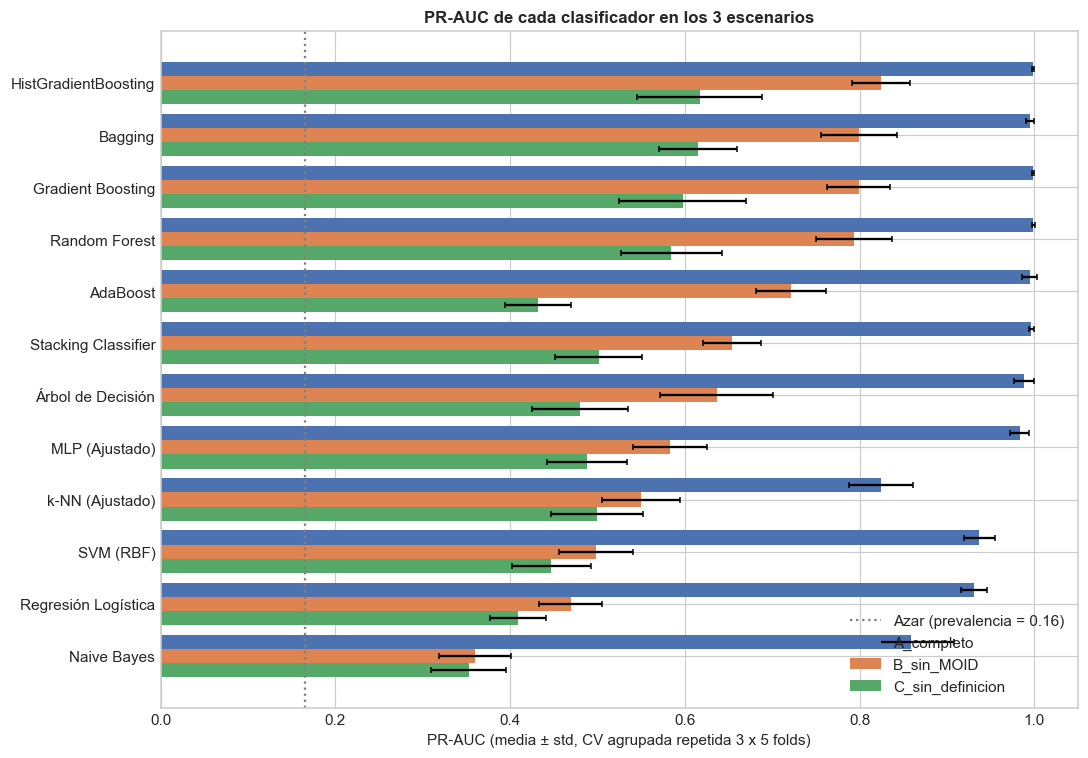

In [18]:
# 4.4 PR-AUC por escenario y caída respecto al escenario A
pivot_pr = df_bench_all.pivot(index='Modelo', columns='Escenario', values='pr_auc')[list(ESCENARIOS)]
pivot_pr['Caída A→B'] = pivot_pr['A_completo'] - pivot_pr['B_sin_MOID']
pivot_pr['Caída A→C'] = pivot_pr['A_completo'] - pivot_pr['C_sin_definicion']
pivot_pr = pivot_pr.sort_values('B_sin_MOID', ascending=False)
display(pivot_pr.round(4))

# Gráfica comparativa con barras de error (± 1 desviación estándar)
modelos_graf = [m for m in pivot_pr.index if m != 'Baseline (Mayoritaria)']
paleta_esc = {'A_completo': '#4C72B0', 'B_sin_MOID': '#DD8452', 'C_sin_definicion': '#55A868'}
alto = 0.27
fig, ax = plt.subplots(figsize=(10, 7))
for j, esc in enumerate(ESCENARIOS):
    sub = df_bench_all[df_bench_all['Escenario'] == esc].set_index('Modelo').loc[modelos_graf]
    pos = np.arange(len(modelos_graf)) + (j - 1) * alto
    ax.barh(pos, sub['pr_auc'], height=alto, xerr=sub['pr_auc_std'], capsize=2, color=paleta_esc[esc], label=esc)
ax.set_yticks(np.arange(len(modelos_graf)))
ax.set_yticklabels(modelos_graf)
ax.invert_yaxis()
ax.axvline(y_train_arr.mean(), color='gray', ls=':', label=f'Azar (prevalencia = {y_train_arr.mean():.2f})')
ax.set_xlim(0, 1.05)
ax.set_xlabel('PR-AUC (media ± std, CV agrupada repetida 3 x 5 folds)')
ax.set_title('PR-AUC de cada clasificador en los 3 escenarios', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

<a id="s5"></a>
## 5. Evaluación (Configure & Build)

<a id="s5-1"></a>
### 5.1 Umbral F2 en Validación y tasa de alertas

En cada escenario (A, B y C) tomamos el ganador de [4.3](#s4-3) con sus hiperparámetros de [4.2](#s4-2), lo entrenamos con todo Train y escogemos el umbral de decisión en Validación.

El umbral de 0.5 supone que los dos errores cuestan lo mismo, y aquí no es así: dejar pasar un asteroide peligroso es mucho peor que una falsa alarma. Escogemos el umbral que maximiza $F_2 = \frac{5 \cdot P \cdot R}{4P + R}$ en Validación. La **tasa de alertas** es el porcentaje de acercamientos que el modelo marca como peligrosos con ese umbral; es lo que tendría que revisar un equipo de seguimiento y sirve como referencia para el monitoreo de la sección [7](#s7).

Test todavía no se usa: el modelo, los hiperparámetros y el umbral quedan fijos con Train y Validación.

El modelo que desplegamos es el del escenario B: el MOID no siempre está calculado para un asteroide recién descubierto, y en el escenario A el modelo solo repite la regla de la NASA.

In [19]:
# 5.1 Ganador de cada escenario: entrenamiento con Train, umbral F2 en Validación y tasa de alertas
def umbral_f2(y_true: np.ndarray, probs: np.ndarray) -> tuple[float, float]:
    """Devuelve (umbral, F2) que maximiza F2 sobre la curva Precision-Recall."""
    precs, recs, thrs = precision_recall_curve(y_true, probs)
    p, r = precs[:-1], recs[:-1]
    f2 = np.where((4 * p + r) > 0, 5 * p * r / (4 * p + r + 1e-12), 0)
    i = int(np.argmax(f2))
    return float(thrs[i]), float(f2[i])


def metricas_binarias(y_true: np.ndarray, probs: np.ndarray, umbral: float) -> dict[str, float]:
    """Métricas de decisión con un umbral dado + métricas de ranking independientes del umbral."""
    pred = (probs >= umbral).astype(int)
    return {
        'pr_auc': average_precision_score(y_true, probs),
        'roc_auc': roc_auc_score(y_true, probs),
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0),
        'f1': f1_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred, zero_division=0),
        'precision': precision_score(y_true, pred, zero_division=0),
        'accuracy': accuracy_score(y_true, pred),
        'falsos_negativos': int(((pred == 0) & (y_true == 1)).sum()),
        'falsos_positivos': int(((pred == 1) & (y_true == 0)).sum()),
        'tasa_alertas': float(pred.mean())
    }


resultados_esc: dict[str, dict[str, Any]] = {}
for esc in ESCENARIOS:
    ganador = rankings[esc].loc[rankings[esc]['Modelo'] != 'Baseline (Mayoritaria)', 'Modelo'].iloc[0]
    modelo = modelo_ajustado(esc, ganador).fit(X_esc(esc, idx_train), y_train_arr)
    probs_val = modelo.predict_proba(X_esc(esc, idx_val))[:, 1]
    umbral, f2_val = umbral_f2(y_val_arr, probs_val)
    fila_cv = rankings[esc].set_index('Modelo').loc[ganador]
    resultados_esc[esc] = {
        'escenario': esc, 'modelo_nombre': ganador, 'modelo': modelo, 'mejores_params': AJUSTE[esc][ganador]['params'],
        'cv_pr_auc_base': AJUSTE[esc][ganador]['cv_pr_auc_base'], 'cv_pr_auc_ajustado': float(fila_cv['pr_auc']),
        'cv_pr_auc_std': float(fila_cv['pr_auc_std']), 'umbral': umbral, 'f2_val': f2_val, 'probs_val': probs_val,
        'val': metricas_binarias(y_val_arr, probs_val, umbral), 'val_umbral_05': metricas_binarias(y_val_arr, probs_val, 0.5)
    }

tabla_umbral = pd.DataFrame([{
    'Escenario': esc, 'Modelo': r['modelo_nombre'],
    'CV PR-AUC (media ± std)': f"{r['cv_pr_auc_ajustado']:.4f} ± {r['cv_pr_auc_std']:.4f}",
    'Umbral F2 (Val)': round(r['umbral'], 3), 'Val PR-AUC': r['val']['pr_auc'], 'Val Recall': r['val']['recall'],
    'Val Precision': r['val']['precision'], 'Val F2': r['val']['f2'], 'Tasa de alertas (Val)': r['val']['tasa_alertas'],
    'Val Recall (umbral 0.5)': r['val_umbral_05']['recall'], 'Tasa de alertas (Val, umbral 0.5)': r['val_umbral_05']['tasa_alertas']
} for esc, r in resultados_esc.items()]).set_index('Escenario')
display(tabla_umbral.round(4))
for esc, r in resultados_esc.items():
    print(f'{esc:17s} -> {r["modelo_nombre"]}: {r["mejores_params"]}')

,Modelo,CV PR-AUC (media ± std),Umbral F2 (Val),Val PR-AUC,Val Recall,Val Precision,Val F2,Tasa de alertas (Val),Val Recall (umbral 0.5),"Tasa de alertas (Val, umbral 0.5)"
Escenario,,,,,,,,,,
A_completo,HistGradientBoosting,0.9985 ± 0.0014,0.299,1.0000,1.0000,1.0000,1.0000,0.1472,0.9897,0.1457
B_sin_MOID,HistGradientBoosting,0.8245 ± 0.0327,0.004,0.8982,0.9691,0.6351,0.8769,0.2246,0.8351,0.1533
C_sin_definicion,HistGradientBoosting,0.6170 ± 0.0717,0.131,0.6429,0.9485,0.4000,0.7443,0.3490,0.6289,0.1730


A_completo        -> HistGradientBoosting: {'clf__class_weight': 'balanced', 'clf__l2_regularization': 0.0010672476836323724, 'clf__learning_rate': 0.021288914225337758, 'clf__max_features': 0.7623873301291946, 'clf__max_iter': 269, 'clf__max_leaf_nodes': 35, 'clf__min_samples_leaf': 64}
B_sin_MOID        -> HistGradientBoosting: {'clf__class_weight': None, 'clf__l2_regularization': 0.003008686821445846, 'clf__learning_rate': 0.13799741637040025, 'clf__max_features': 0.8803925243084487, 'clf__max_iter': 317, 'clf__max_leaf_nodes': 62, 'clf__min_samples_leaf': 18}
C_sin_definicion  -> HistGradientBoosting: {'clf__class_weight': 'balanced', 'clf__l2_regularization': 0.008532678095658722, 'clf__learning_rate': 0.025561799929622115, 'clf__max_features': 0.8091930046665436, 'clf__max_iter': 463, 'clf__max_leaf_nodes': 62, 'clf__min_samples_leaf': 68}


<a id="s5-2"></a>
### 5.2 Pruebas de sobreajuste

Con el modelo y el umbral fijos, y sin mirar Test, revisamos si el modelo memoriza en vez de generalizar:

1. **Diferencia entre entrenamiento y validación cruzada.** Para cada modelo de [4.3](#s4-3) comparamos el PR-AUC sobre los datos con los que se entrenó y sobre los folds que no vio. Una diferencia grande indica sobreajuste.
2. **Curva de aprendizaje** del modelo del escenario B: PR-AUC en entrenamiento y en validación cruzada a medida que crece la cantidad de datos de entrenamiento. Si las dos curvas se acercan y se aplanan, más datos no cambiarían mucho; si la de validación sigue subiendo, más datos ayudarían.
3. **Importancia por permutación en Validación** del modelo desplegado: desordenamos una variable a la vez y medimos cuánto baja el PR-AUC. Muestra en qué se apoya el modelo con datos que no usó para entrenar.

Diferencia de PR-AUC entre entrenamiento y validación cruzada (Train - CV):


Escenario,A_completo,B_sin_MOID,C_sin_definicion
Modelo,,,
Regresión Logística,0.0115,0.0081,0.0035
Naive Bayes,0.0202,0.0111,0.0047
AdaBoost,0.0047,0.0811,0.0697
HistGradientBoosting,0.0014,0.1755,0.3829
Bagging,0.0048,0.2007,0.3853
Gradient Boosting,0.0016,0.2012,0.4023
Random Forest,0.0011,0.2062,0.3700
Árbol de Decisión,0.0102,0.2288,0.2299
Stacking Classifier,0.0033,0.2387,0.3428


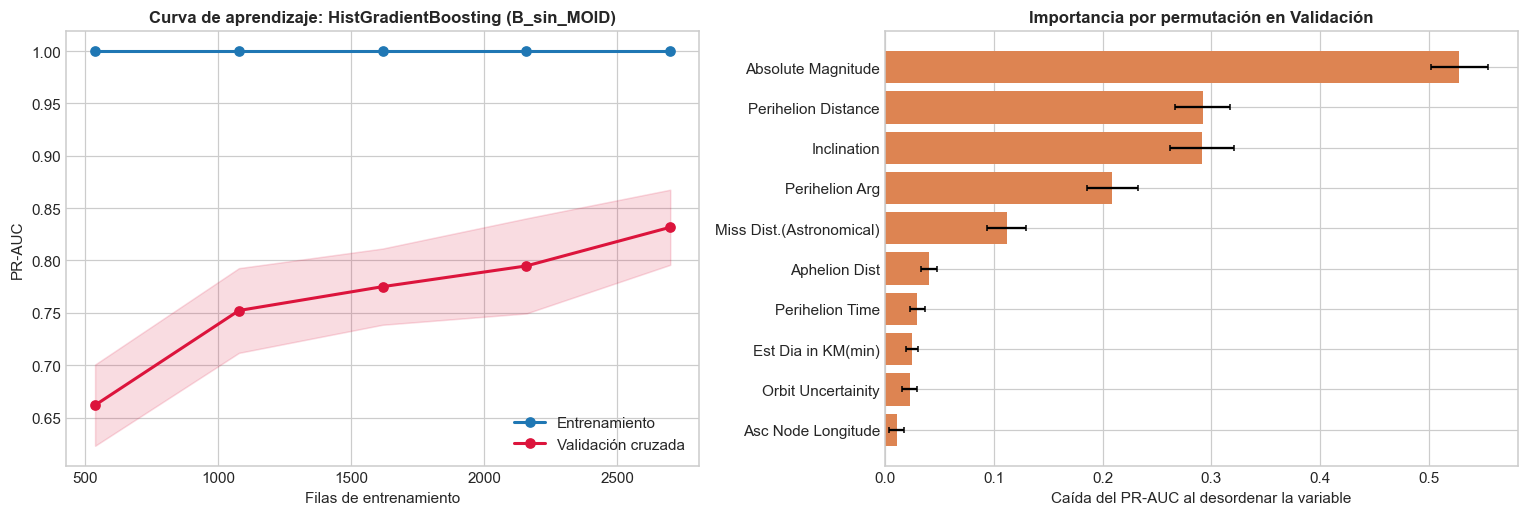

,Filas de entrenamiento,PR-AUC Train,PR-AUC CV,Desv. CV
0,539,1.0,0.6619,0.0388
1,1079,1.0,0.7522,0.0404
2,1618,1.0,0.7750,0.0364
3,2158,1.0,0.7948,0.0454
4,2698,1.0,0.8317,0.0359


,Caída de PR-AUC,Desv.
Absolute Magnitude,0.5281,0.0262
Perihelion Distance,0.2920,0.0255
Inclination,0.2914,0.0292
Perihelion Arg,0.2089,0.0237
Miss Dist.(Astronomical),0.1118,0.0178
Aphelion Dist,0.0403,0.0070
Perihelion Time,0.0295,0.0071
Est Dia in KM(min),0.0245,0.0051
Orbit Uncertainity,0.0223,0.0066
Asc Node Longitude,0.0103,0.0066


In [20]:
# 5.2 Sobreajuste: brecha Train - CV, curva de aprendizaje e importancia por permutación (modelo del escenario B)
brecha = df_bench_all[df_bench_all['Modelo'] != 'Baseline (Mayoritaria)'].assign(
    brecha=lambda d: d['train_pr_auc'] - d['pr_auc'])
BRECHA_TRAIN_CV = brecha.pivot(index='Modelo', columns='Escenario', values='brecha')[list(ESCENARIOS)]
print('Diferencia de PR-AUC entre entrenamiento y validación cruzada (Train - CV):')
display(BRECHA_TRAIN_CV.sort_values(ESCENARIO_DESPLIEGUE).round(4))

final_b = resultados_esc[ESCENARIO_DESPLIEGUE]
X_tr_b = X_esc(ESCENARIO_DESPLIEGUE, idx_train)
tam_lc, pr_tr_lc, pr_cv_lc = learning_curve(
    modelo_ajustado(ESCENARIO_DESPLIEGUE, final_b['modelo_nombre']), X_tr_b, y_train_arr, groups=g_train_arr, cv=cv_5f,
    scoring='average_precision', train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=SEED, n_jobs=-1)
CURVA_APRENDIZAJE = pd.DataFrame({'Filas de entrenamiento': tam_lc, 'PR-AUC Train': pr_tr_lc.mean(1),
                                  'PR-AUC CV': pr_cv_lc.mean(1), 'Desv. CV': pr_cv_lc.std(1)})

perm = permutation_importance(final_b['modelo'], X_esc(ESCENARIO_DESPLIEGUE, idx_val), y_val_arr, scoring='average_precision',
                              n_repeats=10, random_state=SEED, n_jobs=-1)
IMPORTANCIA_PERM = pd.DataFrame({'Caída de PR-AUC': perm.importances_mean, 'Desv.': perm.importances_std},
                                index=X_tr_b.columns).sort_values('Caída de PR-AUC', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(tam_lc, pr_tr_lc.mean(1), marker='o', lw=2, label='Entrenamiento')
axes[0].plot(tam_lc, pr_cv_lc.mean(1), marker='o', lw=2, color='crimson', label='Validación cruzada')
axes[0].fill_between(tam_lc, pr_cv_lc.mean(1) - pr_cv_lc.std(1), pr_cv_lc.mean(1) + pr_cv_lc.std(1), color='crimson', alpha=0.15)
axes[0].set_title(f'Curva de aprendizaje: {final_b["modelo_nombre"]} ({ESCENARIO_DESPLIEGUE})')
axes[0].set_xlabel('Filas de entrenamiento'); axes[0].set_ylabel('PR-AUC'); axes[0].legend(loc='lower right')
top = IMPORTANCIA_PERM.head(10)[::-1]
axes[1].barh(top.index, top['Caída de PR-AUC'], xerr=top['Desv.'], color='#DD8452', capsize=2)
axes[1].set_title('Importancia por permutación en Validación')
axes[1].set_xlabel('Caída del PR-AUC al desordenar la variable')
plt.tight_layout()
plt.show()
display(CURVA_APRENDIZAJE.round(4))
display(IMPORTANCIA_PERM.head(10).round(4))

<a id="s5-3"></a>
### 5.3 Evaluación en Test

Con todo decidido (modelo, hiperparámetros y umbral), evaluamos una sola vez en Test. Para cada escenario reportamos las métricas con el umbral F2 escogido en Validación y con el umbral de 0.5, cuántos peligrosos se escapan con cada uno y la tasa de alertas.

In [21]:
# 5.3 Evaluación en Test (una sola vez, con modelo, hiperparámetros y umbral ya fijos)
for esc, r in resultados_esc.items():
    r['probs_test'] = r['modelo'].predict_proba(X_esc(esc, idx_test))[:, 1]
    r['test'] = metricas_binarias(y_test_arr, r['probs_test'], r['umbral'])
    r['test_umbral_05'] = metricas_binarias(y_test_arr, r['probs_test'], 0.5)
    r['tasa_alertas'] = {'validacion': r['val']['tasa_alertas'], 'test': r['test']['tasa_alertas']}

filas_final = []
for esc, r in resultados_esc.items():
    filas_final.append({
        'Escenario': esc, 'Modelo': r['modelo_nombre'],
        'CV PR-AUC (base → ajustado)': f"{r['cv_pr_auc_base']:.4f} → {r['cv_pr_auc_ajustado']:.4f}",
        'Umbral F2 (Val)': round(r['umbral'], 3),
        'Test PR-AUC': r['test']['pr_auc'], 'Test ROC-AUC': r['test']['roc_auc'],
        'Test F2': r['test']['f2'], 'Test Recall': r['test']['recall'], 'Test Precision': r['test']['precision'],
        'Test F1': r['test']['f1'], 'Test FN': r['test']['falsos_negativos'],
        'Test F2 (umbral 0.5)': r['test_umbral_05']['f2'], 'Test Recall (umbral 0.5)': r['test_umbral_05']['recall'],
        'Test FN (umbral 0.5)': r['test_umbral_05']['falsos_negativos'],
        'Tasa de alertas Val': r['tasa_alertas']['validacion'], 'Tasa de alertas Test': r['tasa_alertas']['test']
    })
df_final = pd.DataFrame(filas_final).set_index('Escenario')
display(df_final.round(4))

# Umbral F2 frente a umbral 0.5 en Test
COMPARACION_UMBRAL = pd.DataFrame([{
    'Escenario': esc, 'Umbral': nombre_u, 'Valor': round(u, 3), 'Recall': m['recall'], 'Precision': m['precision'], 'F2': m['f2'],
    'Peligrosos sin detectar': m['falsos_negativos'], 'Falsas alarmas': m['falsos_positivos'], 'Tasa de alertas': m['tasa_alertas']}
    for esc, r in resultados_esc.items()
    for nombre_u, u, m in [('F2 (Validación)', r['umbral'], r['test']), ('0.5', 0.5, r['test_umbral_05'])]
]).set_index(['Escenario', 'Umbral'])
print(f'Umbral F2 vs 0.5 en Test ({int(y_test_arr.sum())} peligrosos de {len(y_test_arr)} acercamientos):')
display(COMPARACION_UMBRAL.round(4))

,Modelo,CV PR-AUC (base → ajustado),Umbral F2 (Val),Test PR-AUC,Test ROC-AUC,Test F2,Test Recall,Test Precision,Test F1,Test FN,Test F2 (umbral 0.5),Test Recall (umbral 0.5),Test FN (umbral 0.5),Tasa de alertas Val,Tasa de alertas Test
Escenario,,,,,,,,,,,,,,,
A_completo,HistGradientBoosting,0.9958 → 0.9985,0.299,0.9987,0.9997,0.9754,0.9810,0.9537,0.9671,2,0.9791,0.9810,2,0.1472,0.1605
B_sin_MOID,HistGradientBoosting,0.8132 → 0.8245,0.004,0.8369,0.9569,0.7956,0.9048,0.5367,0.6738,10,0.7115,0.7048,31,0.2246,0.2630
C_sin_definicion,HistGradientBoosting,0.6237 → 0.6170,0.131,0.6191,0.8967,0.7046,0.8952,0.3806,0.5341,11,0.6618,0.6857,33,0.3490,0.3670


Umbral F2 vs 0.5 en Test (105 peligrosos de 673 acercamientos):


Valor  Recall  Precision      F2  \
Escenario        Umbral                                              
A_completo       F2 (Validación)  0.299  0.9810     0.9537  0.9754   
                 0.5              0.500  0.9810     0.9717  0.9791   
B_sin_MOID       F2 (Validación)  0.004  0.9048     0.5367  0.7956   
                 0.5              0.500  0.7048     0.7400  0.7115   
C_sin_definicion F2 (Validación)  0.131  0.8952     0.3806  0.7046   
                 0.5              0.500  0.6857     0.5806  0.6618   

                                  Peligrosos sin detectar  Falsas alarmas  \
Escenario        Umbral                                                     
A_completo       F2 (Validación)                        2               5   
                 0.5                                    2               3   
B_sin_MOID       F2 (Validación)                       10              82   
                 0.5                                   31              26   
C_sin_definicion F2 (Validación)                       11             153   
                 0.5                                   33              52   

                                  Tasa de alertas  
Escenario        Umbral                            
A_completo       F2 (Validación)           0.1605  
                 0.5                       0.1575  
B_sin_MOID       F2 (Validación)           0.2630  
                 0.5                       0.1486  
C_sin_definicion F2 (Validación)           0.3670  
                 0.5                       0.1842

<a id="s5-4"></a>
### 5.4 Modelo final (escenario B): umbral, reportes y matrices de confusión

Cómo cambian la precisión, el recall y el F2 según el umbral en Validación; el reporte de clasificación por clase, y las matrices de confusión normalizadas en Validación y en Test con el umbral escogido.

Modelo ganador (B_sin_MOID): HistGradientBoosting | hiperparámetros: {'clf__class_weight': None, 'clf__l2_regularization': 0.003008686821445846, 'clf__learning_rate': 0.13799741637040025, 'clf__max_features': 0.8803925243084487, 'clf__max_iter': 317, 'clf__max_leaf_nodes': 62, 'clf__min_samples_leaf': 18}
Umbral óptimo calibrado en Validación (máx F2): 0.004 (F2 Val = 0.8769)


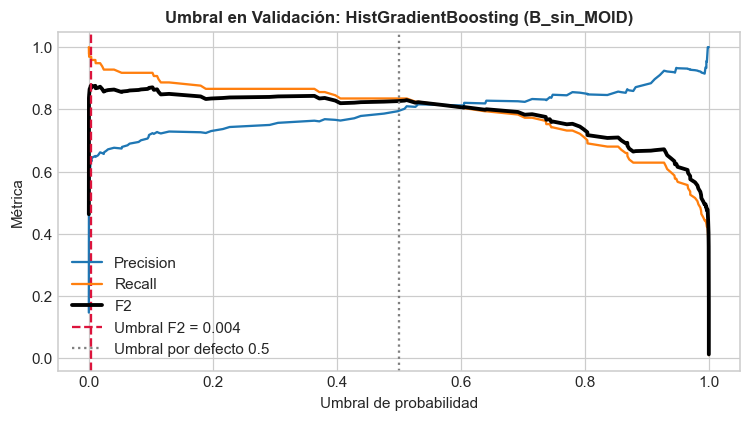


Reporte de clasificación en VALIDACIÓN (umbral 0.004)
              precision    recall  f1-score   support

No Peligroso     0.9941    0.9039    0.9469       562
   Peligroso     0.6351    0.9691    0.7673        97

    accuracy                         0.9135       659
   macro avg     0.8146    0.9365    0.8571       659
weighted avg     0.9413    0.9135    0.9205       659

PR-AUC: 0.8982 | ROC-AUC: 0.9797 | F2: 0.8769

Reporte de clasificación en PRUEBA (TEST) (umbral 0.004)
              precision    recall  f1-score   support

No Peligroso     0.9798    0.8556    0.9135       568
   Peligroso     0.5367    0.9048    0.6738       105

    accuracy                         0.8633       673
   macro avg     0.7583    0.8802    0.7936       673
weighted avg     0.9107    0.8633    0.8761       673

PR-AUC: 0.8369 | ROC-AUC: 0.9569 | F2: 0.7956


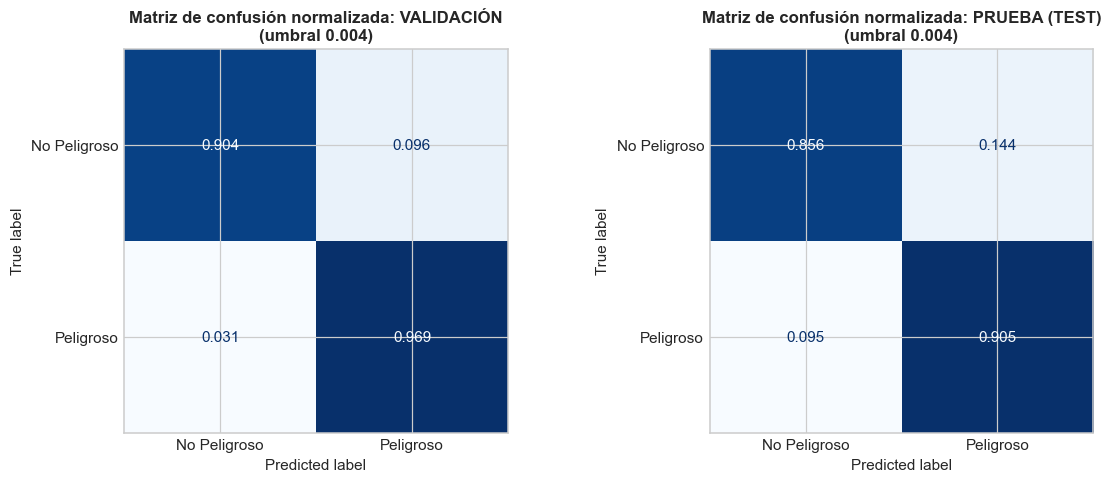

In [22]:
# 5.4 Modelo final: escenario B
final = resultados_esc[ESCENARIO_DESPLIEGUE]
modelo_ganador, opt_thr, mejor_nombre = final['modelo'], final['umbral'], final['modelo_nombre']
COLS_DEPLOY = columnas_escenario(ESCENARIO_DESPLIEGUE)
print(f'Modelo ganador ({ESCENARIO_DESPLIEGUE}): {mejor_nombre} | hiperparámetros: {final["mejores_params"]}')
print(f'Umbral óptimo calibrado en Validación (máx F2): {opt_thr:.3f} (F2 Val = {final["f2_val"]:.4f})')

# Curva F2 / Recall / Precision vs umbral en Validación
precs, recs, thrs = precision_recall_curve(y_val_arr, final['probs_val'])
f2_curve = np.where((4 * precs[:-1] + recs[:-1]) > 0, 5 * precs[:-1] * recs[:-1] / (4 * precs[:-1] + recs[:-1] + 1e-12), 0)
plt.figure(figsize=(8, 4))
plt.plot(thrs, precs[:-1], label='Precision')
plt.plot(thrs, recs[:-1], label='Recall')
plt.plot(thrs, f2_curve, label='F2', lw=2.5, color='black')
plt.axvline(opt_thr, color='crimson', ls='--', label=f'Umbral F2 = {opt_thr:.3f}')
plt.axvline(0.5, color='gray', ls=':', label='Umbral por defecto 0.5')
plt.title(f'Umbral en Validación: {mejor_nombre} ({ESCENARIO_DESPLIEGUE})')
plt.xlabel('Umbral de probabilidad'); plt.ylabel('Métrica'); plt.legend(loc='lower left')
plt.show()

# Reportes de clasificación y matrices de confusión (Validación y Test)
conjuntos_eval = [('VALIDACIÓN', y_val_arr, final['probs_val']), ('PRUEBA (TEST)', y_test_arr, final['probs_test'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (c_name, y_eval, probs_eval) in zip(axes, conjuntos_eval):
    preds_opt = (probs_eval >= opt_thr).astype(int)
    print(f'\nReporte de clasificación en {c_name} (umbral {opt_thr:.3f})')
    print(classification_report(y_eval, preds_opt, target_names=['No Peligroso', 'Peligroso'], digits=4))
    print(f'PR-AUC: {average_precision_score(y_eval, probs_eval):.4f} | ROC-AUC: {roc_auc_score(y_eval, probs_eval):.4f} | '
          f'F2: {fbeta_score(y_eval, preds_opt, beta=2):.4f}')
    ConfusionMatrixDisplay.from_predictions(
        y_eval, preds_opt, display_labels=['No Peligroso', 'Peligroso'],
        normalize='true', values_format='.3f', cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(f'Matriz de confusión normalizada: {c_name}\n(umbral {opt_thr:.3f})')
plt.tight_layout()
plt.show()

<a id="s5-5"></a>
### 5.5 Curvas ROC y Precision-Recall

1. El modelo final (escenario B) en Validación y en Test.
2. Los ganadores de los tres escenarios en Test, para ver cuánto se pierde al quitar el MOID y luego la definición completa.

En la curva PR la línea de referencia es la proporción de peligrosos, no 0.5. Con clases desbalanceadas esta curva dice más que la ROC.

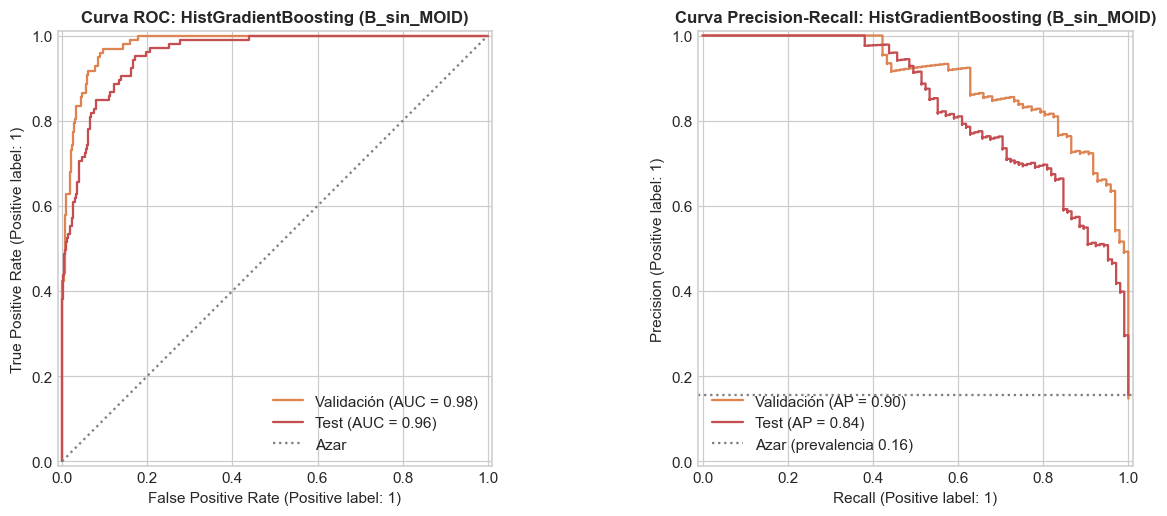

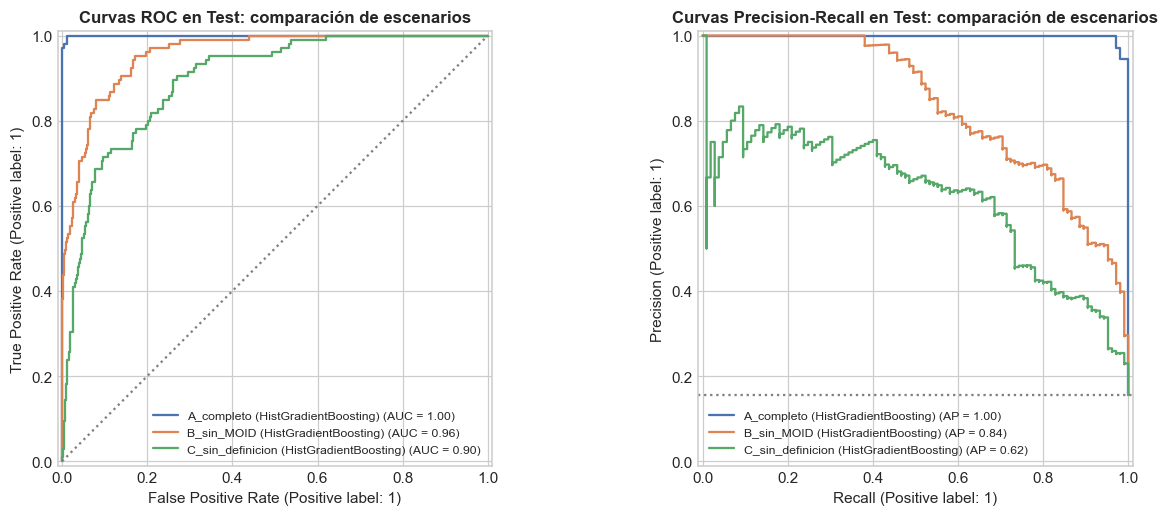

In [23]:
# 5.5 Curvas ROC y PR del modelo final (Validación vs Test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for c_name, y_eval, probs_eval, color in [('Validación', y_val_arr, final['probs_val'], '#DD8452'),
                                          ('Test', y_test_arr, final['probs_test'], '#C44E52')]:
    RocCurveDisplay.from_predictions(y_eval, probs_eval, name=c_name, ax=axes[0], color=color)
    PrecisionRecallDisplay.from_predictions(y_eval, probs_eval, name=c_name, ax=axes[1], color=color)
axes[0].plot([0, 1], [0, 1], ls=':', color='gray', label='Azar')
axes[1].axhline(y_test_arr.mean(), ls=':', color='gray', label=f'Azar (prevalencia {y_test_arr.mean():.2f})')
axes[0].set_title(f'Curva ROC: {mejor_nombre} ({ESCENARIO_DESPLIEGUE})')
axes[1].set_title(f'Curva Precision-Recall: {mejor_nombre} ({ESCENARIO_DESPLIEGUE})')
for ax in axes:
    ax.legend(loc='lower right' if ax is axes[0] else 'lower left')
plt.tight_layout()
plt.show()

# Comparación de los tres escenarios en Test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for esc, r in resultados_esc.items():
    etiqueta = f'{esc} ({r["modelo_nombre"]})'
    RocCurveDisplay.from_predictions(y_test_arr, r['probs_test'], name=etiqueta, ax=axes[0], color=paleta_esc[esc])
    PrecisionRecallDisplay.from_predictions(y_test_arr, r['probs_test'], name=etiqueta, ax=axes[1], color=paleta_esc[esc])
axes[0].plot([0, 1], [0, 1], ls=':', color='gray')
axes[1].axhline(y_test_arr.mean(), ls=':', color='gray')
axes[0].set_title('Curvas ROC en Test: comparación de escenarios')
axes[1].set_title('Curvas Precision-Recall en Test: comparación de escenarios')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

<a id="s5-6"></a>
### 5.6 Intervalos de confianza en Test

Test tiene unos 100 asteroides peligrosos, así que una o dos detecciones mueven las métricas varios puntos. Para saber qué tanto podemos confiar en cada número, repetimos 1,000 veces la evaluación sobre muestras de Test con reemplazo (*bootstrap*). Remuestreamos **asteroides**, no filas, para respetar los grupos. El modelo y el umbral no cambian: solo se recalculan las métricas.

In [24]:
# 5.6 Bootstrap por asteroide sobre Test (modelo y umbral fijos)
def bootstrap_por_grupos(y_true: np.ndarray, probs: np.ndarray, umbral: float, grupos: np.ndarray,
                         n: int = 1000, semilla: int = SEED) -> pd.DataFrame:
    """Métricas en n remuestreos de asteroides (con reemplazo) del conjunto evaluado."""
    rng = np.random.default_rng(semilla)
    unicos = np.unique(grupos)
    filas_de = {g: np.flatnonzero(grupos == g) for g in unicos}
    muestras = []
    for _ in range(n):
        s = np.concatenate([filas_de[g] for g in rng.choice(unicos, len(unicos))])
        if y_true[s].sum() == 0:
            continue
        m = metricas_binarias(y_true[s], probs[s], umbral)
        muestras.append({k: m[k] for k in ['pr_auc', 'roc_auc', 'recall', 'precision', 'f2']})
    return pd.DataFrame(muestras)


g_test_arr = groups[idx_test]
filas_ic = []
for esc, r in resultados_esc.items():
    bs = bootstrap_por_grupos(y_test_arr, r['probs_test'], r['umbral'], g_test_arr)
    for k in bs.columns:
        filas_ic.append({'Escenario': esc, 'Métrica': k, 'Test': r['test'][k],
                         'IC 95% inferior': bs[k].quantile(0.025), 'IC 95% superior': bs[k].quantile(0.975)})
df_ic = pd.DataFrame(filas_ic)
display(df_ic.set_index(['Escenario', 'Métrica']).round(3))

Test  IC 95% inferior  IC 95% superior
Escenario        Métrica                                           
A_completo       pr_auc     0.999            0.996            1.000
                 roc_auc    1.000            0.999            1.000
                 recall     0.981            0.941            1.000
                 precision  0.954            0.908            0.991
                 f2         0.975            0.940            0.997
B_sin_MOID       pr_auc     0.837            0.765            0.901
                 roc_auc    0.957            0.937            0.974
                 recall     0.905            0.844            0.961
                 precision  0.537            0.450            0.634
                 f2         0.796            0.734            0.852
C_sin_definicion pr_auc     0.619            0.487            0.764
                 roc_auc    0.897            0.860            0.930
                 recall     0.895            0.826            0.958
                 precision  0.381            0.311            0.460
                 f2         0.705            0.634            0.772

<a id="s6"></a>
## 6. Despliegue (Deploy)

<a id="s6-1"></a>
### 6.1 Guardar el modelo y las métricas

Guardamos con `joblib` un archivo con todo lo necesario para usar el modelo del escenario B: el pipeline entrenado, las columnas que pide, el umbral, las versiones de las librerías y la distribución de cada variable en entrenamiento (por deciles), que usamos en el monitoreo de la sección [7](#s7). Las métricas quedan en `resultados/metrics_summary.json` y las tablas en `resultados/*.csv`.

In [25]:
# 6.1 Guardar el modelo y exportar las métricas
RUTA_MODELO = Path('model_asteroid_hazard.joblib')
X_train_deploy = X_esc(ESCENARIO_DESPLIEGUE, idx_train)


def referencia_variable(valores: np.ndarray) -> dict[str, list[float]]:
    """Bordes por deciles (únicos, abiertos en los extremos) y proporción de Train en cada intervalo.

    Se guardan las proporciones reales porque en variables discretas varios deciles coinciden
    y los intervalos dejan de contener exactamente el 10% de los datos.
    """
    bordes = np.unique(np.quantile(valores, np.linspace(0, 1, 11)))
    bordes[0], bordes[-1] = -np.inf, np.inf
    proporciones = np.histogram(valores, bins=bordes)[0] / len(valores)
    return {'bordes': bordes.tolist(), 'proporciones': proporciones.tolist()}


artefacto_produccion = {
    'pipeline': modelo_ganador,
    'columnas': COLS_DEPLOY,
    'umbral': opt_thr,
    'modelo': mejor_nombre,
    'hiperparametros': final['mejores_params'],
    'escenario': ESCENARIO_DESPLIEGUE,
    'metodologia': 'ASUM-DM',
    'metricas_test': final['test'],
    'referencia_monitoreo': {c: referencia_variable(X_train_deploy[c].to_numpy()) for c in COLS_DEPLOY},
    'versiones': {'sklearn': sklearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__},
    'seed': SEED,
    'fecha_entrenamiento': datetime.now().isoformat(timespec='seconds')
}
joblib.dump(artefacto_produccion, RUTA_MODELO)
print(f'Modelo guardado en {RUTA_MODELO} ({RUTA_MODELO.stat().st_size / 1024:.1f} KB)')


def a_json(obj: Any) -> Any:
    """Convierte tipos numpy / tuplas a tipos nativos serializables en JSON."""
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return str(obj)


metrics_summary = {
    'metodologia': 'ASUM-DM',
    'dataset': {'filas': int(len(data)), 'asteroides_unicos': int(data['Neo Reference ID'].nunique()),
                'prevalencia_peligrosos': float(y.mean()), 'acuerdo_regla_cneos': ACUERDO_REGLA},
    'particion': {'train': int(len(idx_train)), 'validacion': int(len(idx_val)), 'test': int(len(idx_test))},
    'fuga_por_agrupamiento_inflado_f1_puntos': INFLADO_FUGA,
    'escalador_elegido': NOMBRE_ESCALADOR,
    'pca_componentes_95': K95,
    'moid_desde_orbita': {'correlacion': CORR_MOID, 'acuerdo_umbral_005': ACUERDO_MOID,
                          'cv': df_geo.reset_index().to_dict(orient='records')},
    'ajuste_hiperparametros': {'combinaciones_por_familia': N_COMBINACIONES,
                               'resultados': df_ajuste.to_dict(orient='records')},
    'cv_repetida': {'semillas': SEMILLAS_CV, 'folds': 5},
    'sobreajuste': {'brecha_train_cv': BRECHA_TRAIN_CV.to_dict(),
                    'curva_aprendizaje': CURVA_APRENDIZAJE.to_dict(orient='list'),
                    'importancia_permutacion': IMPORTANCIA_PERM['Caída de PR-AUC'].to_dict()},
    'umbral_f2_vs_05': COMPARACION_UMBRAL.reset_index().to_dict(orient='records'),
    'intervalos_test': df_ic.to_dict(orient='records'),
    'seleccion_rasgos': {'subconjuntos': subconjuntos, 'cv': df_sel_eval.reset_index().to_dict(orient='records')},
    'benchmark_cv': df_bench_all.to_dict(orient='records'),
    'evaluacion_por_escenario': {
        esc: {k: r[k] for k in ['modelo_nombre', 'mejores_params', 'cv_pr_auc_base', 'cv_pr_auc_ajustado',
                                'umbral', 'val', 'test', 'test_umbral_05', 'cv_pr_auc_std', 'f2_val', 'tasa_alertas']}
        for esc, r in resultados_esc.items()
    },
    'modelo_desplegado': {'escenario': ESCENARIO_DESPLIEGUE, 'modelo': mejor_nombre, 'umbral': opt_thr,
                          'archivo': str(RUTA_MODELO)}
}
(RESULTADOS / 'metrics_summary.json').write_text(json.dumps(metrics_summary, indent=2, ensure_ascii=False, default=a_json), encoding='utf-8')
df_bench_all.to_csv(RESULTADOS / 'benchmark_cv.csv', index=False)
df_final.to_csv(RESULTADOS / 'evaluacion_test_por_escenario.csv')
df_sel_eval.to_csv(RESULTADOS / 'seleccion_rasgos_cv.csv')
df_scaling_res.to_csv(RESULTADOS / 'escalado_cv.csv', index=False)
df_geo.reset_index().to_csv(RESULTADOS / 'geometria_orbital_cv.csv', index=False)
df_ic.to_csv(RESULTADOS / 'intervalos_confianza_test.csv', index=False)
print(f'Archivos en resultados/: {sorted(p.name for p in RESULTADOS.iterdir())}')

Modelo guardado en model_asteroid_hazard.joblib (1738.5 KB)
Archivos en resultados/: ['benchmark_cv.csv', 'escalado_cv.csv', 'evaluacion_test_por_escenario.csv', 'geometria_orbital_cv.csv', 'intervalos_confianza_test.csv', 'jpl_benchmark_cv.csv', 'jpl_evaluacion_test.csv', 'jpl_intervalos_confianza_test.csv', 'jpl_metrics_summary.json', 'jpl_test_por_calidad_orbita.csv', 'metrics_summary.json', 'presentacion_jpl.json', 'presentacion_principal.json', 'seleccion_rasgos_cv.csv']


<a id="s6-2"></a>
### 6.2 Función de predicción

`predecir_peligro_asteroide()` recibe filas tal como vienen en `nasa.csv` (las 40 columnas, o al menos las que usa el modelo), revisa que no falte ninguna columna y que todas sean numéricas, y devuelve la probabilidad de ser peligroso y la decisión con el umbral calibrado.

In [26]:
# 6.2 Función de predicción
def predecir_peligro_asteroide(filas_df: pd.DataFrame, ruta_modelo: str | Path = RUTA_MODELO) -> pd.DataFrame:
    """Predice la peligrosidad de asteroides a partir de filas crudas del catálogo NASA.

    Args:
        filas_df: DataFrame con, al menos, las columnas usadas por el modelo.
        ruta_modelo: ruta del artefacto serializado con joblib.

    Returns:
        DataFrame con el identificador, la probabilidad de ser peligroso y la decisión según el umbral calibrado.

    Raises:
        ValueError: si faltan columnas requeridas o alguna no es numérica.
    """
    art = joblib.load(ruta_modelo)
    cols, pipe, thr = art['columnas'], art['pipeline'], art['umbral']

    faltantes = [c for c in cols if c not in filas_df.columns]
    if faltantes:
        raise ValueError(f'Faltan {len(faltantes)} columnas requeridas por el modelo: {faltantes}')
    no_numericas = [c for c in cols if not pd.api.types.is_numeric_dtype(filas_df[c])]
    if no_numericas:
        raise ValueError(f'Columnas no numéricas: {no_numericas}')

    probs = pipe.predict_proba(filas_df[cols])[:, 1]
    ids = (filas_df['Neo Reference ID'].values if 'Neo Reference ID' in filas_df.columns
           else np.arange(len(filas_df)))
    return pd.DataFrame({
        'Neo Reference ID': ids,
        'Peligroso': probs >= thr,
        'Probabilidad': np.round(probs, 4),
        'Umbral Aplicado': round(thr, 4)
    })


# Prueba con 6 acercamientos nunca vistos de Test (3 peligrosos y 3 no peligrosos), filas crudas de 40 columnas
test_crudo = data.iloc[idx_test]
sample_cruda = pd.concat([test_crudo[test_crudo[TARGET] == c].sample(3, random_state=SEED) for c in (1, 0)])
resultado_inferencia = predecir_peligro_asteroide(sample_cruda)
resultado_inferencia['Etiqueta Real'] = sample_cruda[TARGET].astype(bool).values
print('Predicción con 6 acercamientos de Test (filas crudas):')
display(resultado_inferencia[['Neo Reference ID', 'Etiqueta Real', 'Peligroso', 'Probabilidad', 'Umbral Aplicado']])

# Si falta una columna, la función debe rechazar la fila con un error claro
try:
    predecir_peligro_asteroide(sample_cruda.drop(columns=['Eccentricity']))
except ValueError as err:
    print(f'La función rechaza la fila incompleta: {err}')

Predicción con 6 acercamientos de Test (filas crudas):


,Neo Reference ID,Etiqueta Real,Peligroso,Probabilidad,Umbral Aplicado
0,2162361,True,True,1.0000,0.0038
1,2215588,True,True,1.0000,0.0038
2,3714452,True,True,0.9998,0.0038
3,3656925,False,True,0.2887,0.0038
4,3605565,False,False,0.0000,0.0038
5,2168791,False,False,0.0000,0.0038


La función rechaza la fila incompleta: Faltan 1 columnas requeridas por el modelo: ['Eccentricity']


<a id="s7"></a>
## 7. Monitoreo (Operate & Optimize)

Un modelo en uso se puede degradar si cambian los asteroides que le llegan: telescopios más sensibles detectan objetos más pequeños o más lejanos, cambian los instrumentos, etc. Aquí definimos cómo detectarlo y cuándo volver a entrenar.

<a id="s7-1"></a>
### 7.1 Drift de datos con PSI

El PSI (*Population Stability Index*) compara la distribución de cada variable en un lote de producción con la de entrenamiento, usando los intervalos por deciles guardados en el archivo del modelo:

$$PSI = \sum_{i} (p_{lote,i} - p_{ref,i}) \cdot \ln\frac{p_{lote,i}}{p_{ref,i}}$$

Se suele leer así: menos de 0.1, estable; entre 0.1 y 0.25, cambio moderado; 0.25 o más, drift. Para probarlo usamos el conjunto de Test como si fuera un lote de producción.

In [27]:
# 7.1 PSI por variable y tasa de alertas
def calcular_psi(referencia: dict[str, list[float]], lote: np.ndarray, eps: float = 1e-4) -> float:
    """Population Stability Index de `lote` frente a la distribución de referencia de Train.

    PSI = sum((p_lote - p_ref) * ln(p_lote / p_ref)) sobre los intervalos guardados en el artefacto.
    """
    p_ref = np.clip(np.asarray(referencia['proporciones']), eps, None)
    p_lote = np.histogram(np.asarray(lote, dtype=float), bins=np.asarray(referencia['bordes']))[0] / len(lote)
    p_lote = np.clip(p_lote, eps, None)
    return float(np.sum((p_lote - p_ref) * np.log(p_lote / p_ref)))


def nivel_psi(psi: float) -> str:
    """Interpretación estándar del PSI."""
    return 'Estable' if psi < 0.1 else ('Moderado' if psi < 0.25 else 'DRIFT')


# Usamos los asteroides de Test como si fueran un lote de producción
art_monitor = joblib.load(RUTA_MODELO)
lote_prueba = data.iloc[idx_test]
df_psi = pd.DataFrame({
    'PSI': {c: calcular_psi(art_monitor['referencia_monitoreo'][c], lote_prueba[c]) for c in art_monitor['columnas']}
}).sort_values('PSI', ascending=False)
df_psi['Estado'] = df_psi['PSI'].map(nivel_psi)
display(df_psi.round(4))

# Drift de predicción: la referencia es la tasa de alertas esperada con el umbral calibrado (medida en Validación),
# no la prevalencia, porque un umbral bajo orientado a Recall marca deliberadamente más asteroides.
TASA_ALERTAS_REF = float((final['probs_val'] >= opt_thr).mean())
tasa_alertas = float(predecir_peligro_asteroide(lote_prueba)['Peligroso'].mean())
desvio_pp = 100 * (tasa_alertas - TASA_ALERTAS_REF)
print(f'Tasa de alertas en el lote: {tasa_alertas:.1%} | esperada (Validación): {TASA_ALERTAS_REF:.1%} | '
      f'desvío: {desvio_pp:+.1f} pp -> {"ALERTA" if abs(desvio_pp) > 5 else "dentro de tolerancia (±5 pp)"}')
print(f'(Prevalencia real de peligrosos en Train: {y_train_arr.mean():.1%})')

,PSI,Estado
Perihelion Arg,0.0461,Estable
Asc Node Longitude,0.0381,Estable
Perihelion Distance,0.0381,Estable
Mean Anomaly,0.0336,Estable
Relative Velocity km per sec,0.0302,Estable
Semi Major Axis,0.0269,Estable
Orbital Period,0.0269,Estable
Mean Motion,0.0267,Estable
Perihelion Time,0.0256,Estable
Inclination,0.0217,Estable


Tasa de alertas en el lote: 26.3% | esperada (Validación): 22.5% | desvío: +3.8 pp -> dentro de tolerancia (±5 pp)
(Prevalencia real de peligrosos en Train: 16.5%)


<a id="s7-2"></a>
### 7.2 Plan de monitoreo

| Qué vigilamos | Cómo | Cuándo actuar |
| :--- | :--- | :--- |
| Drift de datos | PSI de cada variable del lote frente a la distribución de entrenamiento guardada en el modelo | PSI > 0.25 en una variable importante según SHAP: revisar. En 2 o más variables: reentrenar |
| Drift de predicciones | Porcentaje de alertas del lote frente al esperado con el umbral calibrado (medido en Validación) | Diferencia de más de 5 puntos porcentuales en 2 lotes seguidos |
| Desempeño real | Cuando CNEOS publique la clasificación oficial, recalcular Recall, $F_2$ y PR-AUC | Recall más de 5 puntos por debajo del de Test, o cualquier falso negativo con $H \le 18$ (más de 1 km) |
| Datos de entrada | La revisión de columnas de `predecir_peligro_asteroide()` y el conteo de valores imputados | Si faltan columnas: bloquear. Si más del 5% está imputado: alerta |
| Umbral | Recalibrar el umbral $F_2$ con el último lote etiquetado | Si el umbral óptimo se mueve más de 0.1 |

**Para reentrenar:** juntar entrenamiento, validación y los lotes de producción ya etiquetados, manteniendo la partición por `Neo Reference ID`; repetir el ajuste y la comparación de modelos, recalibrar el umbral en otra validación y guardar otra versión del archivo (la fecha, las versiones y las métricas quedan registradas en el `.joblib`). La versión reentrenada solo reemplaza a la que está en uso si iguala o supera su Recall y su $F_2$ en un mismo Test.

<a id="s8"></a>
## 8. Resultados y conclusiones

<a id="s8-1"></a>
### 8.1 Cifras clave

Las cifras que citamos en las conclusiones salen de esta tabla.

In [28]:
# 8.1 Cifras clave (de aquí salen los números de las conclusiones)
r_A, r_B, r_C = (resultados_esc[e] for e in ESCENARIOS)


def ic(esc: str, metrica: str) -> str:
    fila = df_ic[(df_ic['Escenario'] == esc) & (df_ic['Métrica'] == metrica)].iloc[0]
    return f"{fila['IC 95% inferior']:.3f} a {fila['IC 95% superior']:.3f}"


segundo_b = rankings[ESCENARIO_DESPLIEGUE].iloc[1]
resumen = {
    'Acuerdo regla CNEOS vs etiqueta': f'{ACUERDO_REGLA:.2%}',
    'Inflado F1 por CV ingenua (A / B / C, puntos)': ' / '.join(f'{INFLADO_FUGA[e]:+.2f}' for e in ESCENARIOS),
    'Escalador elegido': NOMBRE_ESCALADOR,
    'Componentes PCA para >=95% varianza (Esc. B)': f'{K95} de {len(COLS_B)}',
    'Mejor método de selección (CV PR-AUC, Esc. B)': f'{df_sel_eval.index[0]} ({df_sel_eval["pr_auc"].iloc[0]:.4f})',
    'Top-3 SHAP Escenario A': ', '.join(rankings_shap['A_completo'].head(3).index),
    'Top-3 SHAP Escenario B': ', '.join(rankings_shap[ESCENARIO_DESPLIEGUE].head(3).index),
    'MOID calculado vs MOID del dataset': f'correlación {CORR_MOID:.4f}, mismo lado de 0.05 UA en el {ACUERDO_MOID:.1%}',
    'CV PR-AUC B / B + geometría / A (HistGB)': ' / '.join(f'{v:.4f}' for v in df_geo['pr_auc']),
    'Ganador A / B / C': f"{r_A['modelo_nombre']} / {r_B['modelo_nombre']} / {r_C['modelo_nombre']}",
    'CV PR-AUC ganador A / B / C (media ± std)': ' / '.join(f"{r['cv_pr_auc_ajustado']:.4f} ± {r['cv_pr_auc_std']:.4f}" for r in (r_A, r_B, r_C)),
    'Segundo en B y diferencia de PR-AUC': f"{segundo_b['Modelo']} ({r_B['cv_pr_auc_ajustado'] - segundo_b['pr_auc']:.4f})",
    'Brecha Train - CV del ganador B': f"{BRECHA_TRAIN_CV.loc[r_B['modelo_nombre'], ESCENARIO_DESPLIEGUE]:.4f}",
    'Test PR-AUC A / B / C': f"{r_A['test']['pr_auc']:.4f} / {r_B['test']['pr_auc']:.4f} / {r_C['test']['pr_auc']:.4f}",
    'Test Recall A / B / C (umbral F2)': f"{r_A['test']['recall']:.4f} / {r_B['test']['recall']:.4f} / {r_C['test']['recall']:.4f}",
    'IC 95% PR-AUC Test (B)': ic(ESCENARIO_DESPLIEGUE, 'pr_auc'),
    'IC 95% Recall Test (B)': ic(ESCENARIO_DESPLIEGUE, 'recall'),
    'Modelo desplegado (B): umbral F2': f'{opt_thr:.3f}',
    'Modelo desplegado (B): Test F2 umbral F2 vs 0.5': f"{r_B['test']['f2']:.4f} vs {r_B['test_umbral_05']['f2']:.4f}",
    'Modelo desplegado (B): FN en Test umbral F2 vs 0.5': f"{r_B['test']['falsos_negativos']} vs {r_B['test_umbral_05']['falsos_negativos']} "
                                                         f"(de {int(y_test_arr.sum())} peligrosos)",
    'Modelo desplegado (B): tasa de alertas Val / Test': f"{r_B['tasa_alertas']['validacion']:.1%} / {r_B['tasa_alertas']['test']:.1%}",
    'Variables con drift (PSI > 0.25)': ', '.join(df_psi.index[df_psi['PSI'] > 0.25]) or 'ninguna'
}
display(pd.Series(resumen, name='Valor').to_frame())

,Valor
Acuerdo regla CNEOS vs etiqueta,99.55%
"Inflado F1 por CV ingenua (A / B / C, puntos)",+0.82 / +16.18 / +21.86
Escalador elegido,StandardScaler
Componentes PCA para >=95% varianza (Esc. B),10 de 18
"Mejor método de selección (CV PR-AUC, Esc. B)","Wrapper (RFE, k de RFECV) (0.7483)"
Top-3 SHAP Escenario A,"Minimum Orbit Intersection, Absolute Magnitude, Est Dia in KM(min)"
Top-3 SHAP Escenario B,"Absolute Magnitude, Est Dia in KM(min), Inclination"
MOID calculado vs MOID del dataset,"correlación 0.9964, mismo lado de 0.05 UA en el 97.1%"
CV PR-AUC B / B + geometría / A (HistGB),0.8220 / 0.9729 / 0.9968
Ganador A / B / C,HistGradientBoosting / HistGradientBoosting / HistGradientBoosting


<a id="s8-2"></a>
### 8.2 Datos para la presentación

Exportamos a `resultados/presentacion_principal.json` los datos de las gráficas de la presentación web. Son números ya calculados arriba; la presentación solo los dibuja.

In [29]:
# 8.2 Datos de las gráficas para la presentación web (carpeta presentacion/)
# Solo se exportan números ya calculados arriba: la presentación los dibuja, nunca los recalcula.
def _confusion(y_true: np.ndarray, probs: np.ndarray, umbral: float) -> dict[str, int]:
    """Conteos de la matriz de confusión con un umbral dado."""
    pred = (probs >= umbral).astype(int)
    return {'vn': int(((pred == 0) & (y_true == 0)).sum()), 'fp': int(((pred == 1) & (y_true == 0)).sum()),
            'fn': int(((pred == 0) & (y_true == 1)).sum()), 'vp': int(((pred == 1) & (y_true == 1)).sum())}


def _indices(n: int, puntos: int) -> np.ndarray:
    """Índices equiespaciados (con extremos) para aligerar curvas largas."""
    return np.unique(np.linspace(0, n - 1, min(puntos, n)).astype(int))


def _curva_pr(y_true: np.ndarray, probs: np.ndarray, puntos: int = 80) -> dict[str, list[float]]:
    p, r, _ = precision_recall_curve(y_true, probs)
    i = _indices(len(p), puntos)
    return {'precision': p[i].round(4).tolist(), 'recall': r[i].round(4).tolist()}


precs_v, recs_v, thrs_v = precision_recall_curve(y_val_arr, final['probs_val'])
p_v, r_v = precs_v[:-1], recs_v[:-1]
f2_v = np.where((4 * p_v + r_v) > 0, 5 * p_v * r_v / (4 * p_v + r_v + 1e-12), 0)
i_v = _indices(len(thrs_v), 150)

presentacion = {
    'clases': {'no_peligroso': int(conteo[0]), 'peligroso': int(conteo[1])},
    'regla_vs_etiqueta': {f'regla_{r}_etiqueta_{e}': int(crosstab_rule.loc[r, e])
                          for r in crosstab_rule.index for e in crosstab_rule.columns},
    'variables_por_escenario': {esc: len(columnas_escenario(esc)) for esc in ESCENARIOS},
    'fuga': tabla_fuga.reset_index().to_dict(orient='records'),
    'phik_hazardous': phik_matrix[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_dict(),
    'pca': {'varianza_individual': pca_full.explained_variance_ratio_.round(4).tolist(),
            'varianza_acumulada': cum_var.round(4).tolist(), 'k95': K95,
            'evaluacion': df_pca_eval.to_dict(orient='records')},
    'shap': {esc: serie.head(10).round(4).to_dict() for esc, serie in rankings_shap.items()},
    'knn': {'k': k_range.tolist(), 'train': np.round(pr_train_k, 4).tolist(), 'cv': pr_cv_k.round(4).tolist(),
            'cv_std': pr_cv_k_std.round(4).tolist(), 'k_optimo_curva': k_opt_curva,
            'gridsearch': {'params': AJUSTE[ESCENARIO_DESPLIEGUE]['k-NN (Ajustado)']['params'],
                           'pr_auc': AJUSTE[ESCENARIO_DESPLIEGUE]['k-NN (Ajustado)']['cv_pr_auc_busqueda']}},
    'umbral_b': {'umbral': thrs_v[i_v].round(4).tolist(), 'precision': p_v[i_v].round(4).tolist(),
                 'recall': r_v[i_v].round(4).tolist(), 'f2': f2_v[i_v].round(4).tolist(),
                 'umbral_f2': opt_thr, 'f2_val': final['f2_val']},
    'confusion_b_test': {'umbral_f2': _confusion(y_test_arr, final['probs_test'], opt_thr),
                         'umbral_05': _confusion(y_test_arr, final['probs_test'], 0.5)},
    'pr_test': {esc: {**_curva_pr(y_test_arr, r['probs_test']), 'modelo': r['modelo_nombre']}
                for esc, r in resultados_esc.items()},
    'prevalencia_test': float(y_test_arr.mean()),
    'psi': df_psi['PSI'].round(4).to_dict(),
    'alertas': {'tasa_lote': tasa_alertas, 'tasa_esperada': TASA_ALERTAS_REF},
    'inferencia': resultado_inferencia[['Neo Reference ID', 'Etiqueta Real', 'Peligroso', 'Probabilidad',
                                        'Umbral Aplicado']].to_dict(orient='records'),
    'modelo': {'archivo': str(RUTA_MODELO), 'tamano_kb': RUTA_MODELO.stat().st_size / 1024, 'columnas': COLS_DEPLOY},
}
(RESULTADOS / 'presentacion_principal.json').write_text(
    json.dumps(presentacion, indent=1, ensure_ascii=False, default=a_json), encoding='utf-8')
print('Guardado resultados/presentacion_principal.json:', ', '.join(presentacion))

Guardado resultados/presentacion_principal.json: clases, regla_vs_etiqueta, variables_por_escenario, fuga, phik_hazardous, pca, shap, knn, umbral_b, confusion_b_test, pr_test, prevalencia_test, psi, alertas, inferencia, modelo


<a id="s8-3"></a>
### 8.3 Conclusiones

Todas las cifras salen de la tabla de [8.1](#s8-1) y de las tablas anteriores (`SEED = 42`).

**1. La etiqueta es una regla física, y el modelo la puede rearmar.** La regla de CNEOS (MOID ≤ 0.05 UA y H ≤ 22.0) coincide con `Hazardous` en el 99.55% de los acercamientos (21 diferencias de 4,687). En el escenario A el ganador logra PR-AUC = 0.999 y Recall = 0.981 en Test: con el MOID, el modelo copia la regla. Además, el MOID sale de la órbita: nuestro cálculo tiene correlación 0.996 con el del dataset y cae del mismo lado de 0.05 UA en el 97.1% de las filas. Con seis variables de geometría orbital, el escenario B pasa de PR-AUC 0.822 a 0.973 en validación cruzada, casi el 0.997 del A ([3.7](#s3-7)). Esas variables quedaron como análisis; el modelo desplegado usa las variables originales.

**2. La fuga por agrupamiento es real y grande.** Con validación cruzada normal (`StratifiedKFold`) el F1 sube +0.8, +16.2 y +21.9 puntos en los escenarios A, B y C frente a la validación agrupada por asteroide. En A casi no se nota porque las variables son muy informativas, pero en los escenarios realistas una partición sin agrupar habría hecho creer que el modelo era mucho mejor.

**3. Preparación de los datos.**
- **Escalado:** `StandardScaler` tuvo el mejor PR-AUC promedio en regresión logística, SVM y k-NN (0.461 frente a 0.256 sin escalar). `RobustScaler` empeoró la SVM (0.299).
- **PCA:** hacen falta 10 de las 18 componentes para el 95% de la varianza, y PCA empeora los resultados (Random Forest: PR-AUC de 0.711 a 0.491 con PCA 95%). La dirección con más varianza no es la que separa las clases, así que el modelo final no usa PCA.
- **Selección de variables:** los cinco métodos coinciden en magnitud absoluta, diámetro, incertidumbre orbital, inclinación y distancia del perihelio. El wrapper fue el mejor (PR-AUC 0.748 frente a 0.708 con todas), pero la diferencia es menor que la desviación estándar entre folds (≈ 0.05), así que el modelo final conserva las 18 variables.
- **SHAP:** en el escenario A domina el MOID (E[|SHAP|] = 0.273, el doble que la siguiente). En el B el peso pasa al tamaño (H 0.109 y diámetro 0.101) y a la forma de la órbita (inclinación 0.055 y perihelio 0.054), con la que el modelo aproxima la cercanía que en A le daba el MOID.

**4. Modelado.** Ajustamos las 13 familias con el mismo presupuesto (20 combinaciones cada una). El ajuste ayudó sobre todo a los modelos que dependen mucho de sus hiperparámetros: k-NN en A pasó de 0.576 a 0.821 y el árbol de decisión en B de 0.448 a 0.667. Con validación cruzada repetida (3 semillas × 5 folds), en el escenario B gana HistGradientBoosting (PR-AUC 0.825 ± 0.033), seguido de Gradient Boosting y Bagging (0.799) y Random Forest (0.794). La diferencia con el segundo (0.026) es menor que la desviación, así que el orden entre los ensambles de árboles es **no concluyente**: los cuatro son buenas opciones. Lo que sí es claro es que los modelos lineales y probabilísticos se caen sin el MOID (regresión logística de 0.931 a 0.469; Naive Bayes de 0.859 a 0.360): la frontera sin el MOID no es lineal.

**5. Sobreajuste.** Los ensambles de árboles llegan a PR-AUC 1.0 en entrenamiento, así que la diferencia con la validación cruzada en B es grande (0.176 para HistGradientBoosting, 0.20–0.21 para Bagging, Gradient Boosting y Random Forest). Aun así, la curva de aprendizaje muestra que el PR-AUC en validación cruzada sigue subiendo con más datos (de 0.662 con el 20% de Train a 0.832 con todo): el límite está en la cantidad de datos más que en el modelo. La importancia por permutación en Validación muestra en qué se apoya el modelo: magnitud absoluta (0.53), perihelio (0.29), inclinación (0.29) y argumento del perihelio (0.21). Son el tamaño y justo los elementos de la órbita con los que se calcula el MOID.

**6. Umbral y tasa de alertas.** El umbral que maximiza F2 en Validación es 0.004. Es tan bajo porque HistGradientBoosting, entrenado sin pesos de clase, da probabilidades muy pequeñas a la mayoría de los asteroides; lo que importa es el orden, no el valor de la probabilidad. Con ese umbral el modelo marca el 22.5% de los acercamientos de Validación y el 26.3% de Test.

**7. Resultado del modelo desplegado (escenario B) en Test.** En 673 acercamientos con 105 peligrosos: **Recall = 0.905** (IC 95%: 0.844 a 0.961), precisión = 0.537, F2 = 0.796, **PR-AUC = 0.837** (IC 95%: 0.765 a 0.901) y ROC-AUC = 0.957. Se escapan 10 de 105 peligrosos. Con el umbral de 0.5 se escaparían 31, a cambio de 26 falsas alarmas en vez de 82: mover el umbral rescata 21 asteroides peligrosos, y una falsa alarma cuesta solo una observación más. El PR-AUC de Validación (0.898) y el de Test (0.837) caen dentro de lo esperable con unos 100 positivos.

**8. Despliegue y monitoreo.** El archivo `model_asteroid_hazard.joblib` guarda el pipeline, las 18 columnas que pide, el umbral, las versiones de las librerías y la distribución de cada variable. La función de predicción revisa la entrada y rechaza filas incompletas. En la prueba de monitoreo todas las variables tienen PSI < 0.05 (estables) y el porcentaje de alertas (26.3%) está 3.8 puntos por encima del esperado (22.5%), dentro de la tolerancia de ±5.

**Limitaciones y trabajo futuro**

1. El MOID se puede calcular desde la órbita ([3.7](#s3-7)). Si está disponible, aplicar la regla es más simple y explicable; el valor del escenario B es mostrar que un modelo puede deducir la cercanía orbital sin esa columna.
2. Test tiene 105 positivos, así que los intervalos de confianza son anchos (PR-AUC de 0.77 a 0.90): una o dos detecciones cambian las métricas varios puntos.
3. Las probabilidades no están calibradas, como muestra el umbral de 0.004; `CalibratedClassifierCV` ayudaría a leerlas como probabilidades reales.
4. La curva de aprendizaje sigue subiendo: con más acercamientos (o reentrenando con Train + Validación una vez fijado el umbral) el modelo probablemente rendiría más.